<a href="https://colab.research.google.com/github/owlmt/QML/blob/main/27_QML_Privacy_Data_Leakage/HybridQNN_SplitLearning_Cowlessur2025.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Hybrid quantum split learning (HQSL) and its reconstruction-attack defence: Cowlessur et al. (2025) step by step

This notebook re-implements, runs and checks the experiments of

> Hevish Cowlessur, Chandra Thapa, Tansu Alpcan and Seyit Camtepe,
> "A hybrid quantum neural network for split learning", *Quantum Machine Intelligence* (2025).
> DOI: https://doi.org/10.1007/s42484-025-00295-z, arXiv:2409.16593v2.

**The story in six sentences.** In *split learning* (SL) a weak client keeps its raw data, runs the first few layers of a neural network, and sends only the
intermediate activations ("smashed data") to a server that runs the rest and returns gradients. The smashed data still leak information: an
honest-but-curious server can train a *reconstruction attack* that turns them back into the client's private images. The paper puts a tiny
**2-qubit quantum layer** at the top of the *server* model (so the client stays purely classical), designs a qubit-efficient way of loading three numbers
into two qubits ("Circuit 6"), and reports that this hybrid server is as good as or slightly better than its classical twin on five datasets (Botnet DGA, Breast Cancer,
MNIST, Fashion-MNIST, Speech Commands), keeps working with up to 100 clients and on noisy simulators/hardware, and can be protected against reconstruction by adding Laplace noise
whose mean is a multiple of 2 pi (the encoding rotation is periodic, so the quantum layer does not notice the shift).

**What the notebook does.**
1. Downloads the five real datasets (public mirrors, cached in `DATA_DIR`) and shows them: shapes, labels, class distributions, labelled 2-D projections.
2. Builds the split models (client network, quantum layer, server head) with an **explicit client/server protocol** (only the smashed data and its gradient cross the cut) and proves it is mathematically identical to centralised training.
3. Implements the quantum layer as a fast exact PyTorch simulator **asserted equal to the PennyLane QNode** (and to a Qiskit circuit) for all five circuits of the paper, and draws the executed circuits.
4. Re-runs the paper's experiments on a CPU simulator: HQSL vs SL (Fig. 7 / Table 5), the circuit study (Table 2), noisy simulators (Fig. 8), many clients (Fig. 9), reconstruction attacks and the Laplace defence (Figs. 13-16, Tables 6-7).
5. Adds an honest classical baseline (RandomForest, SVC), an *adaptive attacker* the paper does not consider, and a claim-by-claim comparison with the paper.

**How to run.** Colab: *Runtime -> Change runtime type -> CPU*, then *Runtime -> Run all* (the install cell may ask for one runtime restart). Everything is downloaded or generated inside the notebook
(about 2.4 GB are *streamed* once for the Speech Commands words yes/no and are never stored). `FAST_MODE = True` (default; roughly 10 minutes on a laptop CPU) uses small budgets;
set it to `False` for the paper's budgets (5 folds, 6,000 images, 50/100 epochs, 200 attacker epochs, 8 client counts), which needs several hours on a CPU.
**What you get:** the tables and figures of the paper re-drawn from your own run, with a verdict per claim ("reproduced", "not reached", "exceeded", "cannot be checked").

## The paper in one page

**Problem.** Split learning lets resource-limited clients (IoT devices) train with a powerful server without sharing raw data, but (i) the server may be quantum while the clients are not, and (ii) the smashed data allow input-reconstruction attacks (data-privacy leakage).

**HQSL architecture (Figs. 1, 6).** Client = classical layers only. Server = **quantum layer** (2 qubits, input = the 3-dimensional smashed data, output = 2 expectation values) followed by classical dense layers. Two variants:
variant 1 (tabular, binary): client 7 -> 32 -> 16 -> 3, server quantum(3->2) -> 64 -> 32 -> 4 -> 1 with dropout 0.5; variant 2 (28 x 28 images, n classes): client 2 x [Conv-ReLU-MaxPool] -> 2 FC -> 3, server quantum(3->2) -> 64 -> 32 -> n.
The classical twin ("SL") replaces the quantum layer by a dense `Linear(3 -> 2)` + ReLU. Training follows Algorithm 1 (gradients through the quantum layer by the parameter-shift rule, Eq. 5-6); several clients are served round-robin (Algorithm 2).

**Quantum layer, "Circuit 6" (Fig. 2b).** Qubit-efficient data loading: each of the 3 features is loaded on *both* qubits with an RX gate, three times along the circuit, interleaved with trainable single-qubit rotations and CZ gates:
2 qubits, depth 8, 6 trainable angles, measurement of sigma_y on each qubit. It was selected among six designs (Appendix C) because it is the only one that beats its classical twin on all datasets; Table 2 compares it with circuits 7-10.

**Data (Table 3).** Botnet DGA (1,000 balanced samples, 7 features, 800/200), Breast Cancer Wisconsin (569, PCA to 7 features, 455/114), MNIST (6,000 images, 4,800/1,200), Fashion-MNIST (6,000, 4,800/1,200), Speech Commands words "yes"/"no" as 28 x 28 spectrograms (7,985, 6,388/1,597). 5-fold cross-validation, Adam (lr 1e-3, 1e-4 for speech), 100 epochs (tabular) / 50 epochs (images).

**Privacy part (Sec. 6).** Threat model: honest-but-curious server with an auxiliary dataset; it trains a reconstruction network on (smashed data, image) pairs and applies it to the client's smashed data at inference time. Three attack decoders (Vepakomma et al. 2020, Li et al. 2018, Balle et al. 2022).
Defence: add Laplace(mu, b) noise to the smashed data. Because RX has period 4 pi, mu = 2 pi k (and small b) leaves the *quantum* layer's input state unchanged, while a classical server is disturbed. Metrics: cosine distance, MSE, DSSIM (and log-spectral distance for spectrograms).

**Claims we can check.**
(C1) HQSL is at least as good as SL on all five datasets; mean gains Fig. 7: Botnet DGA +0.1 / +0.4 points (accuracy / F1), Breast Cancer +0.6 / +0.7, MNIST +0.4 / +0.4, Fashion-MNIST +3 / +4, Speech Commands +1.5 / +1.5. Absolute numbers in Table 5 (circuit 6): e.g. Fashion-MNIST 0.839 / 0.840 (HQSL) vs 0.805 / 0.808 (SL).
(C2) Circuit 6 has depth 8 and 6 parameters and beats circuits 7-10 on Fashion-MNIST (Table 2: 0.839 vs 0.812, 0.823, 0.824, 0.821).
(C3) Splitting does not change the results (split == centralised).
(C4) HQSL still works on noisy back-ends: Botnet DGA accuracy 0.92 (exact) down to 0.89 / 0.83 / 0.72 / 0.60 for depolarising noise p = 0.05 / 0.075 / 0.08 / 0.09 (Fig. 8).
(C5) Accuracy/F1 do not drop with up to K = 100 clients, for both HQSL and SL (Fig. 9).
(C6) With mu in {2 pi, 4 pi} and small b the reconstruction error rises well above its noise-free baseline (Fig. 13, Tables 6-7), more so for the hybrid than for the classical setting.
(C7) With mu = 2 pi / 4 pi and b = 0.01 HQSL keeps its noise-free accuracy while SL's accuracy drops and fluctuates (Figs. 14-15).

### What follows the paper and what had to be chosen

The paper shows its circuits and models as pictures and gives few hyper-parameters. Every choice below is marked `# CHOICE:` in the code.

| Item | Paper | This notebook |
|---|---|---|
| Circuit 6 gates | Fig. 2b (picture): 2 qubits, 3 RX loading points, 6 parameters, depth 8, CZ entanglement | per qubit `RX(x1) RZ(t) | CZ | RX(x2) RY(t) | CZ | RX(x3) RZ(t)`, both qubits receive x1, x2, x3; last CZ omitted (as in the text); measure sigma_y on both qubits. Depth 8 and 6 angles are **asserted** against Table 2 |
| Circuits 7-10 | Figs. 3-4 and text | 7: one layer `U(X)U(Theta)` per qubit with `U = RZ-RY-RZ` (depth 6); 8: features and parameters interleaved + 2 CZ (depth 8); 9/10: three re-uploading layers with / without CZ (depth 20 / 18, 18 angles) |
| Circuit weights | not given | uniform in [0, 2 pi) (PennyLane `TorchLayer` default) |
| Quantum simulation | PennyLane `default.qubit` with PyTorch, 1000 shots, parameter-shift gradients | exact PyTorch state-vector simulator **asserted equal to the PennyLane QNode** (and to Qiskit); exact expectation values for training; autograd gradient **asserted equal** to the parameter-shift gradient. Shot noise (1000 shots) only appears in the Aer study |
| Client, variant 1 | "4 dense layers, 7 -> 3" | `7-32-16-3` (the dimensions of Fig. 6a), ReLU after the first two, no activation on the 3 smashed angles |
| Client, variant 2 | 2 conv filters + MaxPool + 2 FC -> 3 | `Conv(1,8,3)-Conv(8,16,3)`, each with ReLU + MaxPool(2), FC 784 -> 64 -> 3 |
| Server head | listed in Sec. 4.2.2 | as listed; sigmoid + BCE implemented as `BCEWithLogitsLoss` |
| Batch size | not given | 64 |
| Optimiser, epochs, lr | Adam; 100 / 50 epochs; 1e-3 (1e-4 speech) | same in the full run; FAST_MODE uses 40 / 10 epochs, 3 folds, 1,800 images |
| Folds | 5-fold, stratified for images | stratified 5-fold (3 in FAST) for every dataset |
| F1 | not specified | macro-F1 |
| Botnet DGA | 1,000 "equally distributed" samples | 500 + 500 drawn with the master seed from the 5,001-row public file |
| Breast Cancer PCA | PCA to 7 features | StandardScaler -> PCA(7) -> StandardScaler, **fitted on the training part of each fold only** (no leakage) |
| Speech spectrograms | "spectrograms resized to 28 x 28" | STFT (400, hop 160) -> log(1 + 1000 * power) -> bilinear resize -> min-max to [0, 1] |
| Attacker training | model 1: SGD 1e-3 / 0.9, L1, 200 epochs, X_rec = 4/5 of the test fold | same budget in the full run (40 epochs in FAST); batch 32; decoder widths are ours (not given) |
| Reconstruction targets | normalised images | pixels in [0, 1]; absolute MSE / LSD values therefore differ from the paper's, only ratios and directions are comparable |
| DSSIM | defined as `(1 - SSIM)^2` but "0 <= DSSIM <= 0.5" | `(1 - max(SSIM, 0)) / 2` (consistent with the stated range) |
| Real IBM hardware (Fig. 8) | ibm_sherbrooke, ibm_strasbourg, ibm_brussels | cannot be repeated (retired back-ends, no token): skipped unless `IBM_TOKEN` is set; the noisy-simulator rows are reproduced with Qiskit-Aer |
| Fig. 5 (qubits vs 500 h of simulation) | 2-8 qubits, up to 500 h | not run |

## 0. Setup

In [1]:
# Pinned installs. Colab already ships numpy, pandas, scikit-learn, matplotlib, scipy and torch;
# PennyLane (the paper's simulator) and Qiskit + Aer (the paper's noisy-simulator study) are the extras.
# The cell is a no-op on a machine that already has the tested versions.
import importlib, subprocess, sys
try:
    IN_COLAB = "google.colab" in sys.modules
except Exception:
    IN_COLAB = False

def _have(mod, ver):
    try:
        return importlib.import_module(mod).__version__ == ver
    except Exception:
        return False

NEED = []
if not _have("pennylane", "0.45.1"):
    NEED += ["pennylane==0.45.1", "pylatexenc"]
if not _have("qiskit", "2.5.2") or not _have("qiskit_aer", "0.17.2"):
    NEED += ["qiskit==2.5.2", "qiskit-aer==0.17.2", "pylatexenc"]
if NEED and IN_COLAB:
    subprocess.run([sys.executable, "-m", "pip", "-q", "install", *sorted(set(NEED))], check=False)
    print("Installed:", sorted(set(NEED)), "- if Colab asks, restart the runtime once and Run all again.")
elif NEED:
    print("Not on Colab; missing or different versions:", sorted(set(NEED)), "(the notebook will try to use what is installed)")
else:
    print("PennyLane 0.45.1, Qiskit 2.5.2 and Qiskit-Aer 0.17.2 already available; nothing to install.")


PennyLane 0.45.1, Qiskit 2.5.2 and Qiskit-Aer 0.17.2 already available; nothing to install.


### Configuration

Every tunable constant is in the next cell. The committed notebook was executed with the `FAST_MODE` value printed in its first output line; flip it to `False` for the paper's budgets.
`IBM_TOKEN` is optional and only used for the real-hardware cell of section 5. The Hugging Face token is only needed if a download falls back to a Hugging Face mirror (all datasets used here are public);
it is read from the environment variable `HF_TOKEN` or from Colab Secrets and never printed or stored.

In [2]:
# ---------------------------------------------------------------------------------------------
# CONFIGURATION: every tunable constant lives in this cell.
# ---------------------------------------------------------------------------------------------
import os
import numpy as np
FAST_MODE = True              # True: small budgets (class demo, < 10 min on a laptop CPU); False: the paper's budgets as far as a CPU allows
SEED = 42                     # master seed (fold splits, weight initialisation, noise draws)
DATA_DIR = os.environ.get("HQSL_DATA_DIR", "hqsl_data")   # cache for the five datasets (downloaded automatically)
IBM_TOKEN = ""                # unused: the paper's real IBM Quantum runs (ibm_sherbrooke/strasbourg/brussels) are retired/unavailable;
                              # the noisy-simulator part of Fig. 8 is reproduced with Qiskit-Aer instead
N_THREADS = int(os.environ.get("HQSL_THREADS", "2"))      # PyTorch CPU threads (the machine may be shared)

# --- the model (paper Sec. 4) ---
N_QUBITS, SMASHED_DIM = 2, 3  # 2-qubit quantum layer fed with the 3-dimensional smashed data
BATCH = 64                    # CHOICE: the paper does not give a batch size
LR = {"Botnet DGA": 1e-3, "Breast Cancer": 1e-3, "MNIST": 1e-3, "FMNIST": 1e-3, "Speech Commands": 1e-4}   # Adam; paper Sec. 5.1

# --- budgets: paper (FAST_MODE = False) vs quick demo (FAST_MODE = True) ---
if FAST_MODE:
    N_IMG, N_SPEECH = 1500, 1500        # images drawn per dataset (paper: 6,000 / all 7,985 yes+no clips)
    N_FOLDS = 3                         # cross-validation folds (paper: 5)
    EPOCHS = {"tab": 40, "img": 20}     # paper: 100 epochs tabular, 50 epochs images
    CIRC_FOLDS, CIRC_EPOCHS = 2, 10     # Table 2 study (circuits 6-10 on Fashion-MNIST)
    MC_K = (2, 10, 100)                 # numbers of clients (paper: 2,3,4,5,10,20,50,100)
    MC_EPOCHS = {"tab": 8, "img": 6}
    RECON_EPOCHS = 15                   # attacker training epochs (paper: 200)
    RECON_MODELS_2_3 = ("FMNIST",)      # datasets on which reconstruction models 2 and 3 (Appendix E) are also trained
    NOISY_TEST_N = 100                  # circuits per noisy-backend evaluation (first 100 test flows of one Botnet-DGA fold)
else:
    N_IMG, N_SPEECH = 6000, None
    N_FOLDS = 5
    EPOCHS = {"tab": 100, "img": 50}
    CIRC_FOLDS, CIRC_EPOCHS = 5, 50
    MC_K = (2, 3, 4, 5, 10, 20, 50, 100)
    MC_EPOCHS = {"tab": 100, "img": 50}
    RECON_EPOCHS = 200
    RECON_MODELS_2_3 = ("MNIST", "FMNIST", "Speech Commands")
    NOISY_TEST_N = 200

# --- noise study (Fig. 8) and Laplacian defence (Sec. 6) ---
DEPOL_P = (0.05, 0.075, 0.08, 0.09)       # depolarising probabilities of the noisy simulators
SHOTS = 1000                              # paper: 1000 shots per circuit evaluation
NOISE_MU = (0.0, np.pi, 2 * np.pi, 3 * np.pi, 4 * np.pi)
NOISE_B = (0.01, 0.1, 0.5, 1.0)
print(f"FAST_MODE = {FAST_MODE} | folds {N_FOLDS} | images {N_IMG} | epochs {EPOCHS} | recon epochs {RECON_EPOCHS}")


FAST_MODE = True | folds 3 | images 1500 | epochs {'tab': 40, 'img': 20} | recon epochs 15


In [3]:
import io, time, copy, json, math, warnings
import numpy as np, pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import torch, torch.nn as nn, torch.nn.functional as F
import pennylane as qml
import sklearn
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix
warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.dpi": 80, "savefig.dpi": 80, "axes.grid": True, "grid.alpha": 0.25})
os.makedirs(DATA_DIR, exist_ok=True)

# Hugging Face token: only used if a download falls back to a Hugging Face mirror (all datasets here are public).
# A gated dataset would need YOUR token in Colab Secrets (key HF_TOKEN); it is never printed or written anywhere.
HF_TOKEN = os.environ.get("HF_TOKEN")
if HF_TOKEN is None:
    try:
        from google.colab import userdata          # Colab: Settings > Secrets > HF_TOKEN
        HF_TOKEN = userdata.get("HF_TOKEN")
    except Exception:
        HF_TOKEN = None

torch.set_num_threads(max(1, min(N_THREADS, os.cpu_count() or 1)))
np.random.seed(SEED); torch.manual_seed(SEED)
rng_master = np.random.default_rng(SEED)

print("numpy", np.__version__, "| pandas", pd.__version__, "| sklearn", sklearn.__version__, "| matplotlib", matplotlib.__version__)
print("torch", torch.__version__, "| pennylane", qml.__version__)
try:
    import qiskit, qiskit_aer
    print("qiskit", qiskit.__version__, "| qiskit-aer", qiskit_aer.__version__)
    HAVE_AER = True
except Exception as e:
    HAVE_AER = False
    print("Qiskit/Aer not available -> the noisy-simulator study (Fig. 8) is skipped:", e)


numpy 2.5.4 | pandas 3.0.6 | sklearn 1.9.1 | matplotlib 3.11.2
torch 2.14.1+cpu | pennylane 0.45.1
qiskit 2.5.2 | qiskit-aer 0.17.2


## 1. Data

Five real datasets, downloaded from public mirrors and cached in `DATA_DIR`:
* **Botnet DGA** (Suryotrisongko 2022): 5,001 domain-name feature vectors (7 features, label `Result`), from the public Azure blob of the dataset.
* **Breast Cancer Wisconsin (Diagnostic)**: the UCI table that ships with scikit-learn.
* **MNIST** and **Fashion-MNIST**: Keras mirrors (Hugging Face as fallback), 6,000 random images each.
* **Speech Commands v0.02**: the official 2.4 GB archive is streamed and only the 7,985 clips of "yes" (4,044) and "no" (3,941) are kept as 28 x 28 spectrograms (the counts match the paper's 6,388 + 1,597).

In [4]:
import io, tarfile, gzip, struct
import requests

def _download(url, timeout=180):
    r = requests.get(url, timeout=timeout)
    r.raise_for_status()
    return r.content

# ---------------------------------------------------------------------------------------------
# 1) Botnet DGA (tabular, 7 features + label).  Paper: Suryotrisongko (2022), 1000 balanced samples.
# ---------------------------------------------------------------------------------------------
DGA_URL = "https://dgadata.blob.core.windows.net/dga/BotnetDgaDataset_5000_newMethod.csv"

def load_dga():
    cache = os.path.join(DATA_DIR, "BotnetDgaDataset_5000_newMethod.csv")
    if not os.path.exists(cache):
        open(cache, "wb").write(_download(DGA_URL))
    df = pd.read_csv(cache)
    df.columns = [c.strip() for c in df.columns]
    return df

# ---------------------------------------------------------------------------------------------
# 2) Breast Cancer Wisconsin (Diagnostic): the UCI copy that ships with scikit-learn (569 x 30).
# ---------------------------------------------------------------------------------------------
def load_breast():
    from sklearn.datasets import load_breast_cancer
    d = load_breast_cancer(as_frame=True)
    df = d.data.copy()
    df["target"] = d.target.values            # 0 = malignant, 1 = benign (scikit-learn convention)
    return df, list(d.target_names)

# ---------------------------------------------------------------------------------------------
# 3) MNIST and Fashion-MNIST (28 x 28 grey images).  Keras mirror first, Hugging Face as fallback.
# ---------------------------------------------------------------------------------------------
def _read_idx(raw_gz):
    raw = gzip.decompress(raw_gz)
    magic, = struct.unpack(">I", raw[:4]); nd = magic & 0xFF
    dims = struct.unpack(">" + "I" * nd, raw[4:4 + 4 * nd])
    return np.frombuffer(raw, dtype=np.uint8, offset=4 + 4 * nd).reshape(dims)

def _hf_image_dataset(repo, cfg_dir, data_dir):
    from huggingface_hub import hf_hub_download
    from PIL import Image
    out = {}
    for split in ["train", "test"]:
        f = hf_hub_download(repo, f"{cfg_dir}/{split}-00000-of-00001.parquet", repo_type="dataset",
                            cache_dir=data_dir, token=HF_TOKEN)
        df = pd.read_parquet(f)
        out["x_" + split] = np.stack([np.array(Image.open(io.BytesIO(d["bytes"]))) for d in df["image"]])
        out["y_" + split] = df["label"].values.astype(np.uint8)
    return out

def load_mnist():
    cache = os.path.join(DATA_DIR, "mnist.npz")
    if not os.path.exists(cache):
        try:
            open(cache, "wb").write(_download("https://storage.googleapis.com/tensorflow/tf-keras-datasets/mnist.npz"))
        except Exception as e:
            print("MNIST mirror failed (", e, ") -> Hugging Face ylecun/mnist")
            np.savez_compressed(cache, **_hf_image_dataset("ylecun/mnist", "mnist", DATA_DIR))
    d = np.load(cache)
    return d["x_train"], d["y_train"]

FMNIST_NAMES = ["T-shirt/top", "Trouser", "Pullover", "Dress", "Coat", "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"]

def load_fmnist():
    cache = os.path.join(DATA_DIR, "fmnist.npz")
    if not os.path.exists(cache):
        base = "https://storage.googleapis.com/tensorflow/tf-keras-datasets/"
        try:
            xi = _read_idx(_download(base + "train-images-idx3-ubyte.gz"))
            yl = _read_idx(_download(base + "train-labels-idx1-ubyte.gz"))
            np.savez_compressed(cache, x_train=xi, y_train=yl)
        except Exception as e:
            print("Fashion-MNIST mirror failed (", e, ") -> Hugging Face zalando-datasets/fashion_mnist")
            d = _hf_image_dataset("zalando-datasets/fashion_mnist", "fashion_mnist", DATA_DIR)
            np.savez_compressed(cache, x_train=d["x_train"], y_train=d["y_train"])
    d = np.load(cache)
    return d["x_train"], d["y_train"]

# ---------------------------------------------------------------------------------------------
# 4) Speech Commands v0.02, words "yes" / "no" -> log-power spectrograms resized to 28 x 28.
#    The 2.4 GB archive is STREAMED (never stored); only the 7,985 yes/no clips are kept.
# ---------------------------------------------------------------------------------------------
SC_URL = "http://download.tensorflow.org/data/speech_commands_v0.02.tar.gz"

def wav_to_spec28(wave):
    """1-s waveform (int16) -> 28 x 28 spectrogram in [0, 1]. CHOICE: STFT(400, hop 160) -> log(1 + power) -> bilinear resize."""
    w = np.zeros(16000, dtype=np.float32); n = min(len(wave), 16000); w[:n] = wave[:n] / 32768.0
    S = torch.stft(torch.tensor(w), n_fft=400, hop_length=160, window=torch.hann_window(400), return_complex=True).abs() ** 2
    L = torch.log1p(S * 1e3)[None, None]                       # [1, 1, 201, 101]
    L = F.interpolate(L, size=(28, 28), mode="bilinear", antialias=True, align_corners=False)[0, 0]
    L = (L - L.min()) / (L.max() - L.min() + 1e-12)
    return L.numpy().astype(np.float32)

def load_speech():
    cache = os.path.join(DATA_DIR, "speech_yes_no_28x28.npz")
    if not os.path.exists(cache):
        from scipy.io import wavfile
        print("Streaming Speech Commands v0.02 (2.4 GB, keeps only yes/no; takes a few minutes the first time) ...")
        r = requests.get(SC_URL, stream=True, timeout=120); r.raise_for_status()
        X, y, names, waves = [], [], [], {0: [], 1: []}
        with tarfile.open(fileobj=r.raw, mode="r|gz") as tf:
            for m in tf:
                if not m.isfile() or not m.name.endswith(".wav"):
                    continue
                word = m.name.split("/")[-2]
                if word not in ("yes", "no"):
                    continue
                sr, wv = wavfile.read(io.BytesIO(tf.extractfile(m).read()))
                lab = 0 if word == "yes" else 1
                X.append(wav_to_spec28(wv)); y.append(lab); names.append(m.name.split("/")[-1])
                if len(waves[lab]) < 6:
                    waves[lab].append(np.pad(wv, (0, max(0, 16000 - len(wv))))[:16000])
        np.savez_compressed(cache, X=np.stack(X), y=np.array(y, dtype=np.int64), names=np.array(names),
                            w_yes=np.stack(waves[0]), w_no=np.stack(waves[1]))
    d = np.load(cache)
    return d["X"], d["y"], d["w_yes"], d["w_no"]


In [5]:
t0 = time.time()
rng_data = np.random.default_rng(SEED)

dga = load_dga()
DGA_FEATURES = [c for c in dga.columns if c != "Result"]
# CHOICE: the paper "extracts 1000 equally distributed samples": 500 per class, drawn with the master seed.
idx = np.concatenate([rng_data.choice(np.where(dga["Result"].values == k)[0], 500, replace=False) for k in (0, 1)])
idx = rng_data.permutation(idx)
dga_X, dga_y = dga[DGA_FEATURES].values.astype(np.float64)[idx], dga["Result"].values[idx].astype(np.int64)

bc, bc_names = load_breast()
BC_FEATURES = [c for c in bc.columns if c != "target"]
bc_X, bc_y = bc[BC_FEATURES].values.astype(np.float64), bc["target"].values.astype(np.int64)

mn_x, mn_y = load_mnist()
sel = rng_data.choice(len(mn_x), N_IMG, replace=False)                       # paper: 6,000 random samples with a fixed seed
mn_X, mn_Y = (mn_x[sel] / 255.0).astype(np.float32), mn_y[sel].astype(np.int64)

fm_x, fm_y = load_fmnist()
sel = rng_data.choice(len(fm_x), N_IMG, replace=False)
fm_X, fm_Y = (fm_x[sel] / 255.0).astype(np.float32), fm_y[sel].astype(np.int64)

sp_x, sp_y, sp_wav_yes, sp_wav_no = load_speech()
if N_SPEECH is not None and N_SPEECH < len(sp_x):
    sel = rng_data.choice(len(sp_x), N_SPEECH, replace=False); sp_X, sp_Y = sp_x[sel], sp_y[sel]
else:
    sp_X, sp_Y = sp_x, sp_y

DATASETS = {
    "Botnet DGA":      dict(kind="tab", X=dga_X, y=dga_y, features=DGA_FEATURES, classes=["Result=0", "Result=1"], n_cls=2, epochs=EPOCHS["tab"], n_pca=None),
    "Breast Cancer":   dict(kind="tab", X=bc_X,  y=bc_y,  features=BC_FEATURES,  classes=["malignant", "benign"], n_cls=2, epochs=EPOCHS["tab"], n_pca=7),
    "MNIST":           dict(kind="img", X=mn_X,  y=mn_Y,  features=None, classes=[str(i) for i in range(10)], n_cls=10, epochs=EPOCHS["img"]),
    "FMNIST":          dict(kind="img", X=fm_X,  y=fm_Y,  features=None, classes=FMNIST_NAMES, n_cls=10, epochs=EPOCHS["img"]),
    "Speech Commands": dict(kind="img", X=sp_X,  y=sp_Y,  features=None, classes=["yes", "no"], n_cls=2, epochs=EPOCHS["img"]),
}
for k, d in DATASETS.items():
    print(f"{k:16s} X {d['X'].shape}  labels {np.bincount(d['y']).tolist()}")
print(f"loaded in {time.time() - t0:.1f}s")


Botnet DGA       X (1000, 7)  labels [500, 500]
Breast Cancer    X (569, 30)  labels [212, 357]
MNIST            X (1500, 28, 28)  labels [143, 152, 169, 139, 144, 139, 153, 153, 164, 144]
FMNIST           X (1500, 28, 28)  labels [148, 147, 147, 149, 145, 147, 138, 165, 167, 147]
Speech Commands  X (1500, 28, 28)  labels [785, 715]
loaded in 4.4s


### Folds and pre-processing

Stratified K-fold splits (`StratifiedKFold`, shuffled with the master seed). `fold_tensors` fits every transform (scaler, PCA) on the **training part of the fold only** and applies it to the test part.

In [6]:
def get_folds(name, n_folds=None):
    d = DATASETS[name]
    skf = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)   # CHOICE: stratified for every dataset (paper: only for the image sets)
    return list(skf.split(d["X"], d["y"]))[: (n_folds or N_FOLDS)]

def fold_tensors(name, tr, te):
    """Pre-processing fitted on the TRAINING part of the fold only.
    tabular: StandardScaler (+ PCA to 7 components for Breast Cancer, then a second StandardScaler);  images: pixels in [0, 1]."""
    d = DATASETS[name]
    if d["kind"] == "tab":
        A, B = d["X"][tr], d["X"][te]
        sc = StandardScaler().fit(A); A, B = sc.transform(A), sc.transform(B)
        if d["n_pca"]:
            pca = PCA(n_components=d["n_pca"], random_state=SEED).fit(A); A, B = pca.transform(A), pca.transform(B)
            sc2 = StandardScaler().fit(A); A, B = sc2.transform(A), sc2.transform(B)
        Xtr, Xte = torch.tensor(A, dtype=torch.float32), torch.tensor(B, dtype=torch.float32)
    else:
        Xtr, Xte = torch.tensor(d["X"][tr])[:, None], torch.tensor(d["X"][te])[:, None]
    return Xtr, torch.tensor(d["y"][tr]), Xte, torch.tensor(d["y"][te])

FOLDS = {name: get_folds(name) for name in DATASETS}
for name, fl in FOLDS.items():
    print(f"{name:16s} {len(fl)} folds; fold-0 train/test = {len(fl[0][0])}/{len(fl[0][1])}")


Botnet DGA       3 folds; fold-0 train/test = 666/334
Breast Cancer    3 folds; fold-0 train/test = 379/190
MNIST            3 folds; fold-0 train/test = 1000/500
FMNIST           3 folds; fold-0 train/test = 1000/500
Speech Commands  3 folds; fold-0 train/test = 1000/500


## Dataset Exploration and Visualisation

Everything below is computed from the **real** samples of the five datasets (no synthetic data): shapes, feature names, original labels and class counts, the real class distributions,
example images / spectrograms, and a 2-D scatter in which every point is a real observation coloured by its ground-truth label. The PCA is fitted on the training split of fold 0 only.
The HQSL model does not feed raw coordinates into the circuit: the angles that enter the RX gates are the 3 *learned* smashed features, which are drawn in section 3 after training.

In [7]:
print("Five REAL datasets, as used by the paper (Table 3). Nothing below is synthetic; labels are the original ground-truth labels.\n")
for name, d in DATASETS.items():
    X, y = d["X"], d["y"]
    counts = np.bincount(y, minlength=d["n_cls"])
    print(f"=== {name} ===")
    print(f"  shape of X       : {X.shape}   ({'tabular' if d['kind']=='tab' else 'images / spectrograms of 28 x 28 pixels'})")
    if d["kind"] == "tab":
        print(f"  feature names    : {d['features']}")
    else:
        print( "  feature names    : pixel_0 ... pixel_783 (784 grey values in [0, 1])")
    print(f"  original labels  : {sorted(set(y.tolist()))} = {d['classes']}")
    print(f"  class counts     : {dict(zip(d['classes'], counts.tolist()))}")
print("\nNote: Breast Cancer is the UCI 'Wisconsin (Diagnostic)' table (569 x 30); the paper reduces it to 7 PCA components.")
print("      Speech Commands = only the words 'yes' (label 0) and 'no' (label 1), as spectrograms resized to 28 x 28.")


Five REAL datasets, as used by the paper (Table 3). Nothing below is synthetic; labels are the original ground-truth labels.

=== Botnet DGA ===
  shape of X       : (1000, 7)   (tabular)
  feature names    : ['Entropy', 'REAlexa', 'MinREBotnets', 'InformationRadius', 'CharLength', 'TreeNewFeature', 'nGramReputation_Alexa']
  original labels  : [0, 1] = ['Result=0', 'Result=1']
  class counts     : {'Result=0': 500, 'Result=1': 500}
=== Breast Cancer ===
  shape of X       : (569, 30)   (tabular)
  feature names    : ['mean radius', 'mean texture', 'mean perimeter', 'mean area', 'mean smoothness', 'mean compactness', 'mean concavity', 'mean concave points', 'mean symmetry', 'mean fractal dimension', 'radius error', 'texture error', 'perimeter error', 'area error', 'smoothness error', 'compactness error', 'concavity error', 'concave points error', 'symmetry error', 'fractal dimension error', 'worst radius', 'worst texture', 'worst perimeter', 'worst area', 'worst smoothness', 'worst com

### Real class distributions

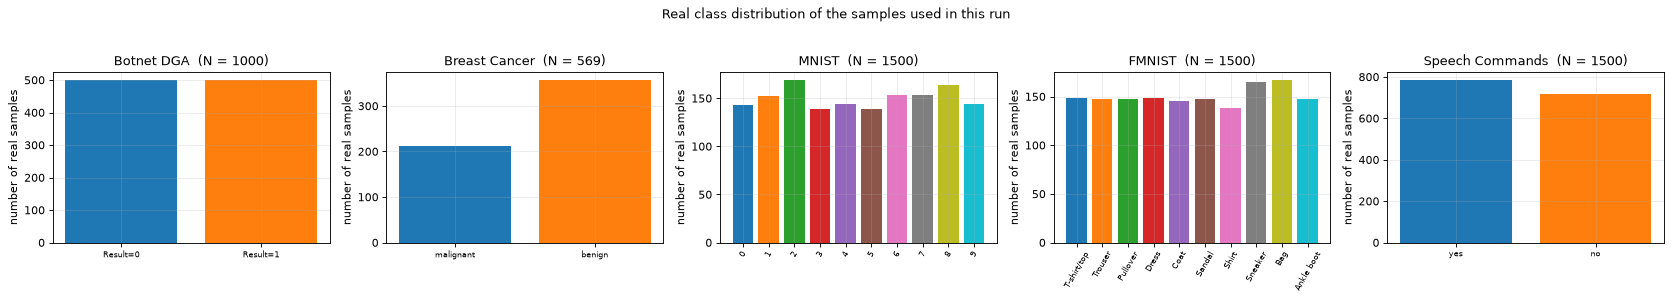

In [8]:
fig, axes = plt.subplots(1, 5, figsize=(21, 3.6))
for ax, (name, d) in zip(axes, DATASETS.items()):
    counts = np.bincount(d["y"], minlength=d["n_cls"])
    ax.bar(range(d["n_cls"]), counts, color=plt.get_cmap("tab10")(np.arange(d["n_cls"])))
    ax.set_xticks(range(d["n_cls"])); ax.set_xticklabels(d["classes"], rotation=60 if d["n_cls"] > 2 else 0, fontsize=7)
    ax.set_title(f"{name}  (N = {len(d['y'])})"); ax.set_ylabel("number of real samples")
plt.suptitle("Real class distribution of the samples used in this run", y=1.03)
plt.tight_layout(); plt.show()


### Real examples

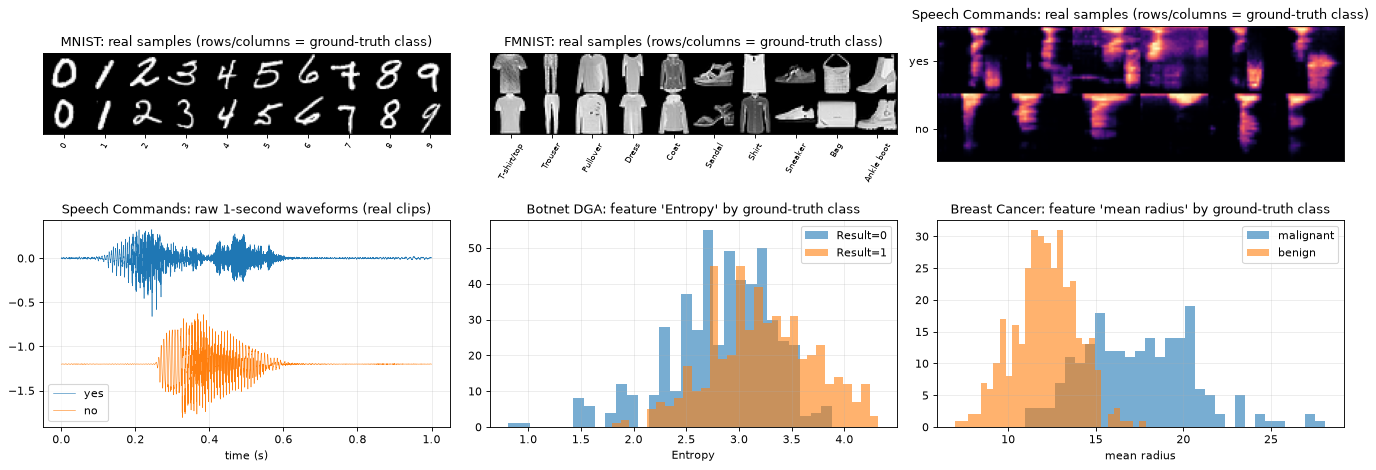

In [9]:
fig, axes = plt.subplots(2, 3, figsize=(17, 6.2))
for j, name in enumerate(["MNIST", "FMNIST", "Speech Commands"]):
    d = DATASETS[name]; grid = np.zeros((2 * 28, 10 * 28)) if d["n_cls"] == 10 else np.zeros((2 * 28, 6 * 28))
    ncol = 10 if d["n_cls"] == 10 else 6
    for c in range(d["n_cls"]):
        ids = np.where(d["y"] == c)[0][: (2 if d["n_cls"] == 10 else 6)]
        for k, i in enumerate(ids):
            r, cc = (k, c) if d["n_cls"] == 10 else (c, k)
            grid[r * 28:(r + 1) * 28, cc * 28:(cc + 1) * 28] = d["X"][i]
    axes[0, j].imshow(grid, cmap="gray" if name != "Speech Commands" else "magma"); axes[0, j].grid(False)
    if d["n_cls"] == 10:
        axes[0, j].set_xticks(np.arange(10) * 28 + 14); axes[0, j].set_xticklabels(d["classes"], rotation=60, fontsize=7); axes[0, j].set_yticks([])
    else:
        axes[0, j].set_yticks([14, 42]); axes[0, j].set_yticklabels(d["classes"]); axes[0, j].set_xticks([])
    axes[0, j].set_title(f"{name}: real samples (rows/columns = ground-truth class)")
# second row: two original waveforms of Speech Commands and the DGA / breast-cancer feature histograms
t = np.arange(16000) / 16000
axes[1, 0].plot(t, sp_wav_yes[0] / 32768, lw=0.5, label="yes"); axes[1, 0].plot(t, sp_wav_no[0] / 32768 - 1.2, lw=0.5, label="no")
axes[1, 0].set_title("Speech Commands: raw 1-second waveforms (real clips)"); axes[1, 0].set_xlabel("time (s)"); axes[1, 0].legend()
for ax, name, feat in [(axes[1, 1], "Botnet DGA", "Entropy"), (axes[1, 2], "Breast Cancer", "mean radius")]:
    d = DATASETS[name]; j_ = d["features"].index(feat)
    for c in range(2):
        ax.hist(d["X"][d["y"] == c, j_], bins=30, alpha=0.6, label=f"{d['classes'][c]}")
    ax.set_title(f"{name}: feature '{feat}' by ground-truth class"); ax.set_xlabel(feat); ax.legend()
plt.tight_layout(); plt.show()


### Labelled 2-D projections of the real observations

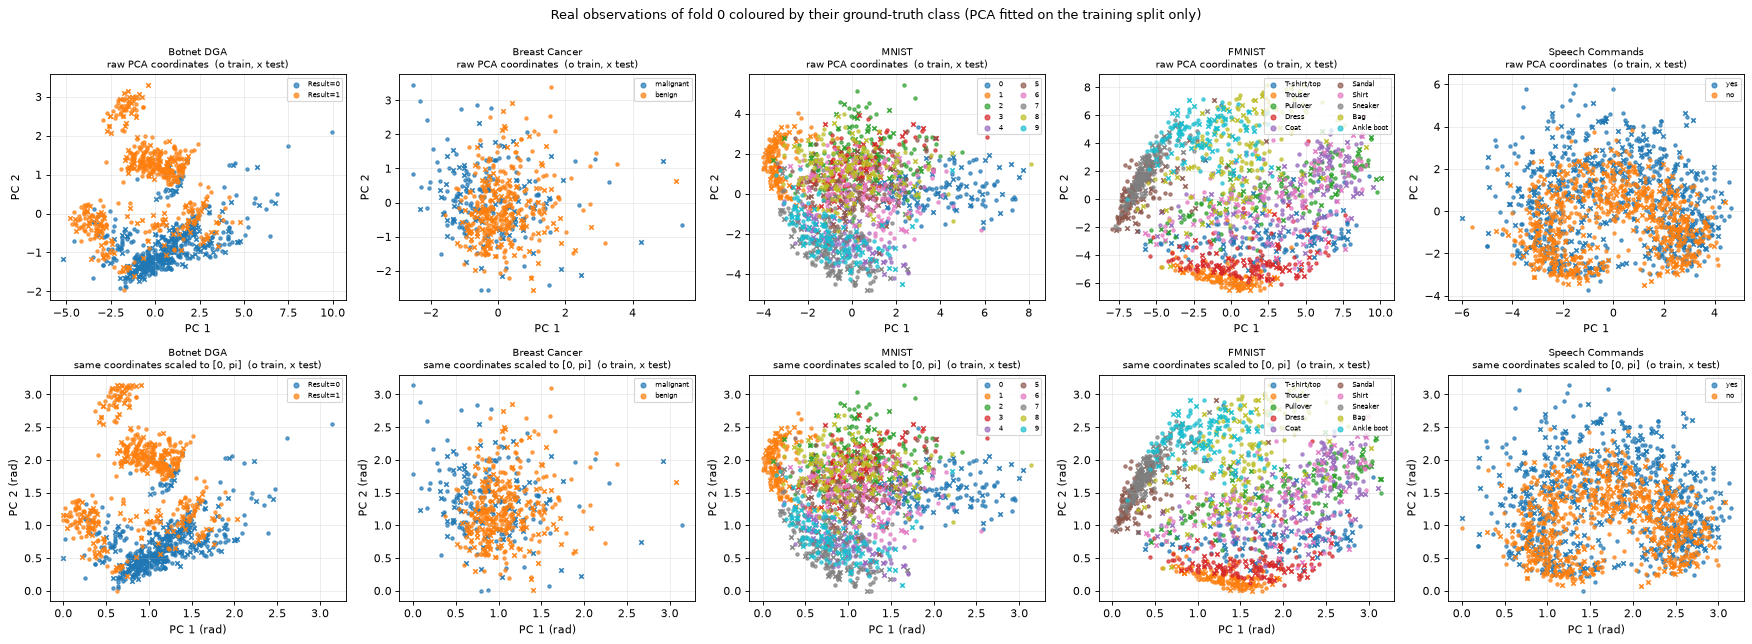

explained variance of the 2 components: {'Botnet DGA': [0.6480000019073486, 0.20600000023841858], 'Breast Cancer': [0.14300000667572021, 0.14300000667572021], 'MNIST': [0.09300000220537186, 0.07199999690055847], 'FMNIST': [0.2879999876022339, 0.1770000010728836], 'Speech Commands': [0.2409999966621399, 0.15600000321865082]}
The HQSL quantum layer does NOT angle-encode these raw coordinates: it angle-encodes the 3 LEARNED smashed-data features z.
Those learned rotation angles are plotted in section 3 once the client networks are trained.


In [10]:
from sklearn.preprocessing import MinMaxScaler
fig, axes = plt.subplots(2, 5, figsize=(22, 8))
PCA2 = {}
for j, (name, d) in enumerate(DATASETS.items()):
    tr, te = FOLDS[name][0]
    Xtr, ytr, Xte, yte = fold_tensors(name, tr, te)
    A, B = Xtr.flatten(1).numpy(), Xte.flatten(1).numpy()                       # fold 0; scaler/PCA(7) already fitted on the training part
    pca = PCA(n_components=2, random_state=SEED).fit(A)                         # 2-D projection fitted on the TRAINING split only
    Ptr, Pte = pca.transform(A), pca.transform(B)
    PCA2[name] = (Ptr, ytr.numpy(), Pte, yte.numpy(), pca.explained_variance_ratio_)
    mm = MinMaxScaler((0, np.pi)).fit(Ptr); Str, Ste = mm.transform(Ptr), np.clip(mm.transform(Pte), 0, np.pi)
    cm = plt.get_cmap("tab10")
    for row, (Ptr_, Pte_, ttl) in enumerate([(Ptr, Pte, "raw PCA coordinates"), (Str, Ste, "same coordinates scaled to [0, pi]")]):
        ax = axes[row, j]
        for c in range(d["n_cls"]):
            ax.scatter(Ptr_[ytr.numpy() == c, 0], Ptr_[ytr.numpy() == c, 1], s=9, color=cm(c), alpha=0.7, label=d["classes"][c])
            ax.scatter(Pte_[yte.numpy() == c, 0], Pte_[yte.numpy() == c, 1], s=16, color=cm(c), marker="x", alpha=0.9)
        ax.set_title(f"{name}\n{ttl}  (o train, x test)", fontsize=9)
        ax.set_xlabel("PC 1" + (" (rad)" if row else "")); ax.set_ylabel("PC 2" + (" (rad)" if row else ""))
        if d["n_cls"] <= 10: ax.legend(fontsize=6, ncol=2 if d["n_cls"] > 2 else 1, markerscale=1.5)
plt.suptitle("Real observations of fold 0 coloured by their ground-truth class (PCA fitted on the training split only)", y=1.0)
plt.tight_layout(); plt.show()
print("explained variance of the 2 components:", {k: np.round(v[4], 3).tolist() for k, v in PCA2.items()})
print("The HQSL quantum layer does NOT angle-encode these raw coordinates: it angle-encodes the 3 LEARNED smashed-data features z.")
print("Those learned rotation angles are plotted in section 3 once the client networks are trained.")


## 2. The split models and the training protocol

`make_pair` builds a client network and a server network. The training step implements Algorithm 1 literally: the client computes the smashed data, **only `Z.detach()` and the labels are handed to the server**, the server back-propagates (including through the quantum layer)
and returns `dL/dZ`, and the client continues the backward pass from there. For several clients (Algorithm 2) the clients are served one after the other in a round-robin and hand the client weights on.
The quantum layer is the exact simulator defined in `c20` (the gate list of the circuit run by a few batched 2 x 2 contractions); the next section proves it equals PennyLane.

In [11]:
# ---------------------------------------------------------------------------------------------
# The quantum layer.  A circuit is a plain list of gates ("gate list"); the SAME list is
#   (a) run by a tiny exact PyTorch state-vector simulator (used for all training: fast, differentiable),
#   (b) turned into a real PennyLane QNode (drawn, and asserted equal to the simulator),
#   (c) turned into a Qiskit circuit for the noisy-simulator study.
# Gate = (name, wire, source); source = ("x", k) -> k-th smashed-data feature, ("w", j) -> j-th trainable angle,
# or None for CZ (wire = (0, 1)).   Wire 0 is the most significant qubit (PennyLane convention).
# ---------------------------------------------------------------------------------------------
PARAM_GATES = ["RZ", "RY", "RZ"]          # RZ-RY-RZ decomposition of an SU(2) gate, paper Eq. (4)

def circuit_spec(cid):
    """Gate lists of the six circuits of Sec. 4.2.1 (2 qubits, 3 features).  Returns (ops, n_weights).
    CHOICE (the paper only shows pictures): see the table in the introduction."""
    ops = []
    if cid == 7:        # one layer U(X)U(Theta) per qubit, no entanglement: depth 6, 6 parameters
        for q in range(2):
            for k, g in enumerate(PARAM_GATES): ops.append((g, q, ("x", k)))
            for k, g in enumerate(PARAM_GATES): ops.append((g, q, ("w", q * 3 + k)))
        return ops, 6
    if cid in (6, 8):   # features and trainable gates interleaved, CZ between the qubits after the 1st and 2nd feature: depth 8, 6 parameters
        enc = ["RX"] * 3 if cid == 6 else PARAM_GATES            # circuit 6 = circuit 8 with RX encoding gates
        for k in range(3):
            for q in range(2):
                ops.append((enc[k], q, ("x", k)))
                ops.append((PARAM_GATES[k], q, ("w", q * 3 + k)))
            if k < 2: ops.append(("CZ", (0, 1), None))           # the last CZ is omitted (paper)
        return ops, 6
    if cid in (9, 10):  # standard data re-uploading: 3 layers L_i = U(X)U(Theta_i); circuit 9 adds CZ after layers 1 and 2
        for l in range(3):
            for q in range(2):
                for k, g in enumerate(PARAM_GATES): ops.append((g, q, ("x", k)))
                for k, g in enumerate(PARAM_GATES): ops.append((g, q, ("w", (l * 2 + q) * 3 + k)))
            if cid == 9 and l < 2: ops.append(("CZ", (0, 1), None))
        return ops, 18
    raise ValueError(cid)

def spec_depth(ops):
    t = [0, 0]
    for g, w, _ in ops:
        if g == "CZ": t = [max(t) + 1] * 2
        else: t[w] += 1
    return max(t)

# ---- exact 2-qubit simulator in PyTorch --------------------------------------------------------
def _rot(g, th):                                  # th: [B] (float64) -> [B, 2, 2] complex128, PennyLane definitions
    c, s = torch.cos(th / 2), torch.sin(th / 2); z = torch.zeros_like(c)
    if g == "RX":   m = [[torch.complex(c, z), torch.complex(z, -s)], [torch.complex(z, -s), torch.complex(c, z)]]
    elif g == "RY": m = [[torch.complex(c, z), torch.complex(-s, z)], [torch.complex(s, z), torch.complex(c, z)]]
    elif g == "RZ": m = [[torch.complex(c, -s), torch.complex(z, z)], [torch.complex(z, z), torch.complex(c, s)]]
    else: raise ValueError(g)
    return torch.stack([torch.stack(r, -1) for r in m], -2)

_Y = torch.tensor([[0, -1j], [1j, 0]], dtype=torch.complex128)
_CZ = torch.tensor([[1, 1], [1, -1]], dtype=torch.complex128)

_SPEC_CACHE = {}

def _compiled(ops):
    """Index tensors so that all rotation matrices of a circuit are built with three vectorised calls (one per gate type)."""
    key = tuple(ops)
    if key not in _SPEC_CACHE:
        rot = [(i, g, s) for i, (g, wire, s) in enumerate(ops) if g != "CZ"]
        pos = {i: n for n, (i, _, _) in enumerate(rot)}
        gather = torch.tensor([s[1] if s[0] == "x" else 3 + s[1] for _, _, s in rot])           # row in cat([x^T, w])
        groups = {g: (torch.tensor([n for n, (_, gg, _) in enumerate(rot) if gg == g]),) for g in ("RX", "RY", "RZ")}
        _SPEC_CACHE[key] = (pos, gather, groups)
    return _SPEC_CACHE[key]

def run_spec(ops, x, w):
    """x: [B, 3] features, w: [n_weights] angles -> [B, 2] expectation values <sigma_y> of qubits 0 and 1."""
    x, w = x.double(), w.double()
    B = x.shape[0]
    pos, gather, groups = _compiled(ops)
    ang = torch.cat([x.T, w[:, None].expand(-1, B)], 0)[gather]                  # [n_rot_gates, B]
    mats = [None] * len(gather)
    for g, (sel,) in groups.items():
        if len(sel):
            U = _rot(g, ang[sel])                                                # [m, B, 2, 2]
            for j, n in enumerate(sel.tolist()): mats[n] = U[j]
    psi = torch.zeros(B, 2, 2, dtype=torch.complex128); psi[:, 0, 0] = 1
    for i, (g, wire, _) in enumerate(ops):
        if g == "CZ":
            psi = psi * _CZ
        elif wire == 0:
            psi = torch.matmul(mats[pos[i]], psi)                                # U on qubit 0
        else:
            psi = torch.matmul(psi, mats[pos[i]].transpose(-1, -2))              # U on qubit 1
    e0 = torch.einsum("bac,ad,bdc->b", psi.conj(), _Y, psi).real
    e1 = torch.einsum("bca,ad,bcd->b", psi.conj(), _Y, psi).real
    return torch.stack([e0, e1], -1)

class QuantumLayer(nn.Module):
    """Trainable quantum layer: 3 smashed-data features -> 2 expectation values <sigma_y>.  Weights ~ U(0, 2 pi) (PennyLane TorchLayer default)."""
    def __init__(self, cid=6):
        super().__init__()
        self.cid = cid
        self.ops, nw = circuit_spec(cid)
        self.weights = nn.Parameter(torch.rand(nw) * 2 * math.pi)
    def forward(self, z):
        return run_spec(self.ops, z, self.weights).to(z.dtype)

class ClassicalLayer(nn.Module):
    """The classical counterpart of the quantum layer (paper, 'Classical Benchmarking of HQSL'): Linear(3 -> 2) + ReLU."""
    def __init__(self):
        super().__init__()
        self.fc = nn.Linear(SMASHED_DIM, N_QUBITS)
    def forward(self, z):
        return F.relu(self.fc(z))

n_q = sum(p.numel() for p in QuantumLayer(6).parameters())
print("Circuit 6: gates", len(circuit_spec(6)[0]), "| trainable angles", n_q, "| depth", spec_depth(circuit_spec(6)[0]))


Circuit 6: gates 14 | trainable angles 6 | depth 8


In [12]:
class ImgClient(nn.Module):
    """HQSL variant 2, client side: 2 x [Conv - ReLU - MaxPool(2, stride 2)] - Flatten - 2 FC layers down to the 3-dimensional smashed data.
    CHOICE: 8 and 16 filters of size 3x3 (the paper gives no filter counts)."""
    def __init__(self):
        super().__init__()
        self.c1, self.c2 = nn.Conv2d(1, 8, 3, padding=1), nn.Conv2d(8, 16, 3, padding=1)
        self.f1, self.f2 = nn.Linear(16 * 7 * 7, 64), nn.Linear(64, SMASHED_DIM)
    def forward(self, x):
        x = (x - 0.5) / 0.5
        x = F.max_pool2d(F.relu(self.c1(x)), 2, 2)
        x = F.max_pool2d(F.relu(self.c2(x)), 2, 2)
        return self.f2(F.relu(self.f1(x.flatten(1))))

def make_client(kind):
    if kind == "tab":      # HQSL variant 1: 7 -> 32 -> 16 -> 3 (dimensions of Fig. 6a); CHOICE: no activation on the 3 smashed angles
        return nn.Sequential(nn.Linear(7, 32), nn.ReLU(), nn.Linear(32, 16), nn.ReLU(), nn.Linear(16, SMASHED_DIM))
    return ImgClient()

def make_server(kind, n_cls, quantum=True, cid=6):
    """Server = [quantum layer | its classical twin] followed by the classical dense layers of Fig. 6.
    Created AFTER the client and the head so that HQSL and SL start from identical classical weights for the same seed."""
    if kind == "tab":      # 2 -> 64 -> 32 -> 4 -> 1, dropout 0.5 on the first two, sigmoid output (folded into the BCE-with-logits loss)
        head = nn.Sequential(nn.Linear(2, 64), nn.ReLU(), nn.Dropout(0.5), nn.Linear(64, 32), nn.ReLU(), nn.Dropout(0.5),
                             nn.Linear(32, 4), nn.ReLU(), nn.Linear(4, 1))
    else:                  # 2 -> 64 -> 32 -> n
        head = nn.Sequential(nn.Linear(2, 64), nn.ReLU(), nn.Linear(64, 32), nn.ReLU(), nn.Linear(32, n_cls))
    mid = QuantumLayer(cid) if quantum else ClassicalLayer()
    return nn.Sequential(mid, head)

def make_pair(name, quantum=True, seed=SEED, cid=6):
    d = DATASETS[name]
    torch.manual_seed(seed)
    client = make_client(d["kind"])
    server = make_server(d["kind"], d["n_cls"], quantum, cid)
    return client, server

def n_params(m):
    return sum(p.numel() for p in m.parameters())

# ---------------------------------------------------------------------------------------------
# Split-learning training.  The "transmission" is explicit: the server only ever sees Z.detach(),
# and the client only ever receives dL/dZ (Algorithm 1 of the paper).
# ---------------------------------------------------------------------------------------------
def task_loss(out, yb, kind):
    if kind == "tab":
        return F.binary_cross_entropy_with_logits(out.squeeze(1), yb.float())   # = sigmoid + BCE (Sec. 5.1)
    return F.cross_entropy(out, yb)

def predict_labels(out, kind):
    return (out.squeeze(1) > 0).long() if kind == "tab" else out.argmax(1)

def split_step(client, server, opt, xb, yb, kind):
    opt.zero_grad()
    Z = client(xb)                                       # client side: forward to the cut layer
    Z_sent = Z.detach().requires_grad_(True)             # -> smashed data crosses the network (labels travel too)
    loss = task_loss(server(Z_sent), yb, kind)           # server side: quantum layer + classical layers
    loss.backward()                                      # server backward (incl. the quantum layer)
    Z.backward(Z_sent.grad)                              # <- gradient dL/dZ crosses back; client backward
    opt.step()
    return loss.item()

def train_split(client, server, X, y, kind, epochs, lr, shards=None, seed=SEED, log_every=0):
    """Algorithm 1 (one client) or Algorithm 2 (round robin over `shards`, a list of index arrays; the client weights are handed on)."""
    opt = torch.optim.Adam(list(client.parameters()) + list(server.parameters()), lr=lr)
    g = torch.Generator().manual_seed(seed)
    n = len(X)
    shards = [np.arange(n)] if shards is None else shards
    hist = []
    for ep in range(epochs):
        client.train(); server.train(); tot, cnt = 0.0, 0
        for sh in shards:                                    # one local epoch per client, clients served one after the other
            perm = torch.as_tensor(sh)[torch.randperm(len(sh), generator=g)]
            for i in range(0, len(perm), BATCH):
                idx = perm[i:i + BATCH]
                tot += split_step(client, server, opt, X[idx], y[idx], kind) * len(idx); cnt += len(idx)
        hist.append(tot / cnt)
        if log_every and (ep % log_every == 0 or ep == epochs - 1):
            print(f"    epoch {ep + 1:3d}  loss {hist[-1]:.4f}")
    return hist

@torch.no_grad()
def infer(client, server, X, kind, noise=None, gen=None, bs=1000, return_z=False):
    """Inference; `noise` = (mu, b) adds Laplace(mu, b) noise to the smashed data (Algorithm 3)."""
    client.eval(); server.eval(); outs, zs = [], []
    for i in range(0, len(X), bs):
        Z = client(X[i:i + bs])
        if noise is not None:
            Z = Z + laplace_noise(Z.shape, noise[0], noise[1], gen)
        zs.append(Z); outs.append(server(Z))
    out = torch.cat(outs)
    return (out, torch.cat(zs)) if return_z else out

def laplace_noise(shape, mu, b, gen=None):
    u = torch.rand(shape, generator=gen) - 0.5
    return mu - b * torch.sign(u) * torch.log1p(-2 * u.abs())          # inverse-CDF sampling of Laplace(mu, b)

def score(client, server, X, y, kind, noise=None, gen=None):
    pred = predict_labels(infer(client, server, X, kind, noise, gen), kind).numpy()
    yt = y.numpy()
    return accuracy_score(yt, pred), f1_score(yt, pred, average="macro")


### Parameter counts and the split == centralised check

In [13]:
rows = []
for name, d in DATASETS.items():
    cl, sv = make_pair(name, True)
    cl2, sv2 = make_pair(name, False)
    rows.append(dict(dataset=name, client_params=n_params(cl), quantum_layer_params=n_params(sv[0]), server_classical_params=n_params(sv[1]),
                     SL_twin_layer_params=n_params(sv2[0])))
print(pd.DataFrame(rows).to_string(index=False))

# Does SPLITTING change anything?  Train one epoch with the explicit client/server protocol and with an ordinary
# centralised autograd step (same seed, same batches) and compare every weight.  Paper: "the test results for the split
# and centralised HQSL versions are identical".
def central_epoch(client, server, X, y, kind, lr, seed):
    opt = torch.optim.Adam(list(client.parameters()) + list(server.parameters()), lr=lr)
    g = torch.Generator().manual_seed(seed); client.train(); server.train()
    perm = torch.randperm(len(X), generator=g)
    for i in range(0, len(perm), BATCH):
        idx = perm[i:i + BATCH]; opt.zero_grad()
        task_loss(server(client(X[idx])), y[idx], kind).backward(); opt.step()

name = "Botnet DGA"; d = DATASETS[name]; tr, te = FOLDS[name][0]
Xtr, ytr, Xte, yte = fold_tensors(name, tr, te)
# (the dropout masks use the global RNG, so it is reset identically before each run)
torch.manual_seed(5); cA, sA = make_pair(name, True); train_split(cA, sA, Xtr, ytr, d["kind"], 1, 1e-3, seed=7)
torch.manual_seed(5); cB, sB = make_pair(name, True); central_epoch(cB, sB, Xtr, ytr, d["kind"], 1e-3, seed=7)
SPLIT_DIFF = diff = max((p - q).abs().max().item() for p, q in zip(list(cA.parameters()) + list(sA.parameters()), list(cB.parameters()) + list(sB.parameters())))
print(f"\nmax |weight difference| split vs centralised after one epoch (incl. the 6 circuit angles): {diff:.2e}")
assert diff < 1e-6, diff
print("split == centralised: OK (the cut layer only moves tensors, it does not change the mathematics)")


        dataset  client_params  quantum_layer_params  server_classical_params  SL_twin_layer_params
     Botnet DGA            835                     6                     2409                     8
  Breast Cancer            835                     6                     2409                     8
          MNIST          51683                     6                     2602                     8
         FMNIST          51683                     6                     2602                     8
Speech Commands          51683                     6                     2338                     8



max |weight difference| split vs centralised after one epoch (incl. the 6 circuit angles): 0.00e+00
split == centralised: OK (the cut layer only moves tensors, it does not change the mathematics)


## Quantum Circuit Architecture

The quantum layer of every HQSL model is one 2-qubit circuit: RX / RZ / RY rotations that load the three smashed-data features `x1, x2, x3` (angle encoding, each feature on *both* qubits), trainable single-qubit rotations,
CZ entanglers, and a `sigma_y` measurement on each qubit (2 outputs). The cells below (i) build the **real PennyLane QNode** from the same gate list that the training simulator runs and **assert** equality to 1e-10 for all five circuits,
(ii) assert that the depth and the number of trainable parameters equal the resource columns of the paper's Table 2, (iii) check the parameter-shift rule against autograd, (iv) draw one circuit per distinct architecture with `qml.draw_mpl`,
and (v) draw the Qiskit version executed by Aer in section 5 and assert its statevector expectation equals the simulator's.

*Assumptions where the paper omits circuit details* (also in the table of the introduction): the figures give no gate-by-gate listing, so the order `RX(x_k)` then `RZ / RY / RZ(theta)` per layer, the CZ positions (after the first and second feature, last CZ omitted),
the sigma_y read-out, and the U(0, 2 pi) initialisation are our reconstruction from the text; they reproduce the stated depth (8) and parameter count (6) exactly. In circuit 7 the first gate acting on |0> is an RZ, which only adds a phase, so feature x1 is invisible to circuits 7, 9 and 10 - one reason why the paper finds them weaker.

In [14]:
def pl_qnode(cid):
    """The REAL PennyLane QNode built from the same gate list that the PyTorch simulator runs (default.qubit, <sigma_y> on both qubits)."""
    ops, nw = circuit_spec(cid)
    dev = qml.device("default.qubit", wires=2)
    @qml.qnode(dev, interface="torch", diff_method="backprop")
    def qn(inputs, weights):
        for g, wire, src in ops:
            if g == "CZ":
                qml.CZ(wires=[0, 1]); continue
            ang = inputs[..., src[1]] if src[0] == "x" else weights[src[1]]
            getattr(qml, g)(ang, wires=wire)
        return [qml.expval(qml.PauliY(0)), qml.expval(qml.PauliY(1))]
    return qn, nw

PAPER_TABLE2 = {   # Table 2: circuit -> (trainable parameters, depth, mean accuracy, mean F1) on Fashion-MNIST
    7: (6, 6, 0.812, 0.815), 8: (6, 8, 0.823, 0.825), 6: (6, 8, 0.839, 0.840), 9: (18, 20, 0.824, 0.826), 10: (18, 18, 0.821, 0.823)}
rows = []
g_eq = torch.Generator().manual_seed(SEED)
for cid in (6, 7, 8, 9, 10):
    qn, nw = pl_qnode(cid)
    x = (torch.randn(16, 3, generator=g_eq, dtype=torch.float64) * 3); w = torch.rand(nw, generator=g_eq, dtype=torch.float64) * 2 * math.pi
    ref = torch.stack(qn(x, w), -1)
    mine = run_spec(circuit_spec(cid)[0], x, w)
    err = (ref - mine).abs().max().item()
    assert err < 1e-10, (cid, err)                                   # PyTorch simulator == PennyLane default.qubit
    try:
        depth_pl = qml.specs(qn)(x[0], w).resources.depth
    except Exception:
        depth_pl = None
    depth = spec_depth(circuit_spec(cid)[0])
    assert depth == PAPER_TABLE2[cid][1] and nw == PAPER_TABLE2[cid][0], (cid, depth, nw)   # matches the resource columns of Table 2
    rows.append(dict(circuit=cid, qubits=2, depth=depth, depth_PennyLane_specs=depth_pl, trainable_parameters=nw, max_diff_vs_simulator=f"{err:.1e}"))
print(pd.DataFrame(rows).to_string(index=False))
print("\nAll five circuits: PyTorch simulator == PennyLane default.qubit (|diff| < 1e-10), and depth / parameter counts equal those of the paper's Table 2.")

# The paper trains with the parameter-shift rule (Eq. 5, 6).  For an exact simulator autograd gives the same gradient:
ops, nw = circuit_spec(6)
xs = torch.randn(4, 3, dtype=torch.float64); ws = (torch.rand(nw, dtype=torch.float64) * 6.28).requires_grad_(True)
run_spec(ops, xs, ws).sum().backward(); g_auto = ws.grad.clone()
g_ps = torch.stack([0.5 * (run_spec(ops, xs, ws.detach() + torch.eye(nw, dtype=torch.float64)[j] * math.pi / 2)
                           - run_spec(ops, xs, ws.detach() - torch.eye(nw, dtype=torch.float64)[j] * math.pi / 2)).sum() for j in range(nw)])
print("max |parameter-shift gradient - autograd gradient| w.r.t. the 6 circuit angles:", (g_ps - g_auto).abs().max().item())
assert (g_ps - g_auto).abs().max().item() < 1e-10


 circuit  qubits  depth  depth_PennyLane_specs  trainable_parameters max_diff_vs_simulator
       6       2      8                      8                     6               2.6e-16
       7       2      6                      6                     6               1.3e-15
       8       2      8                      8                     6               6.7e-16
       9       2     20                     20                    18               4.7e-16
      10       2     18                     18                    18               1.1e-15

All five circuits: PyTorch simulator == PennyLane default.qubit (|diff| < 1e-10), and depth / parameter counts equal those of the paper's Table 2.
max |parameter-shift gradient - autograd gradient| w.r.t. the 6 circuit angles: 3.885780586188048e-16


### The five circuits drawn with PennyLane (the QNodes asserted equal to the simulator above)

Matplotlib is building the font cache; this may take a moment.


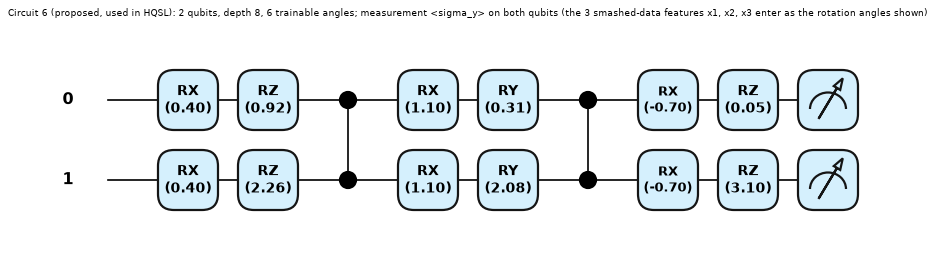

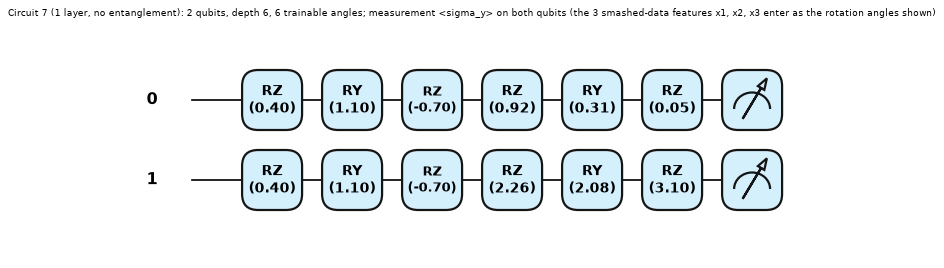

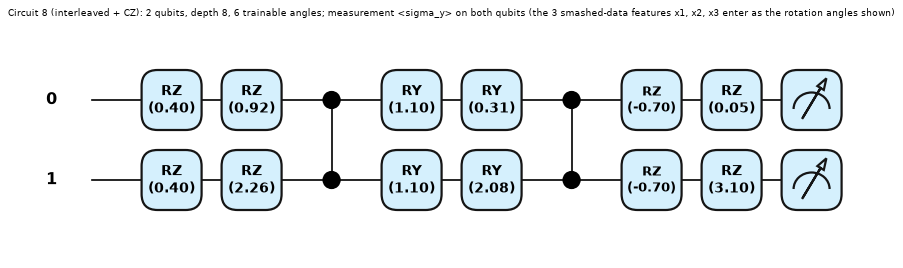

Matplotlib is building the font cache; this may take a moment.


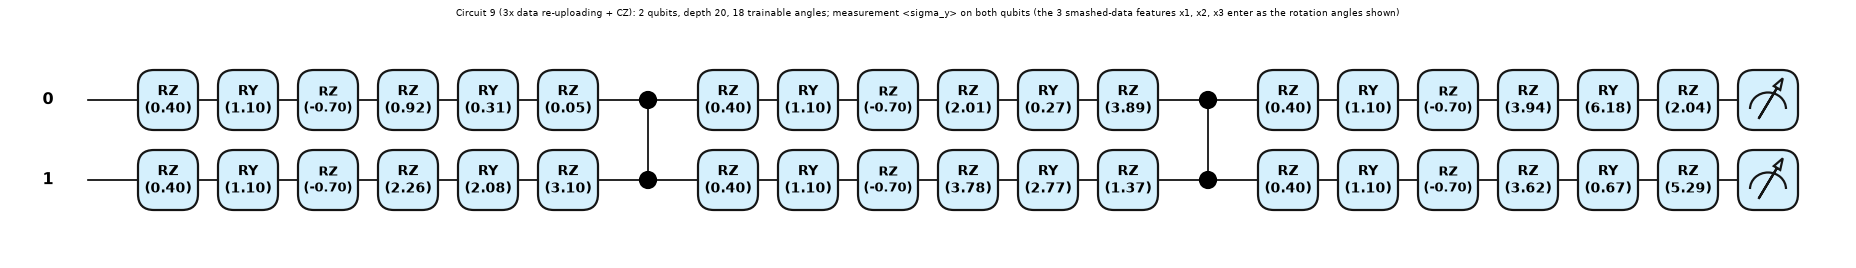

Matplotlib is building the font cache; this may take a moment.


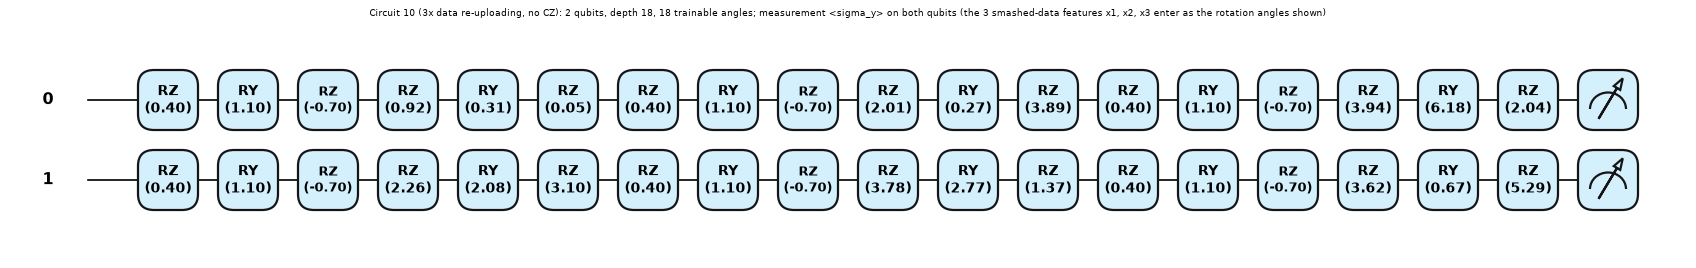

In [15]:
NAMES = {6: "Circuit 6 (proposed, used in HQSL)", 7: "Circuit 7 (1 layer, no entanglement)", 8: "Circuit 8 (interleaved + CZ)",
         9: "Circuit 9 (3x data re-uploading + CZ)", 10: "Circuit 10 (3x data re-uploading, no CZ)"}
x_demo = torch.tensor([0.4, 1.1, -0.7], dtype=torch.float64)
w_demo = torch.rand(18, dtype=torch.float64) * 2 * math.pi
for cid in (6, 7, 8, 9, 10):
    qn, nw = pl_qnode(cid)
    fig, ax = qml.draw_mpl(qn, decimals=2, style="pennylane", fig_options=dict(figsize=(15 if cid in (9, 10) else 11, 2.8)))(x_demo, w_demo[:nw])
    fig.suptitle(f"{NAMES[cid]}: 2 qubits, depth {spec_depth(circuit_spec(cid)[0])}, {nw} trainable angles; measurement <sigma_y> on both qubits "
                 "(the 3 smashed-data features x1, x2, x3 enter as the rotation angles shown)", fontsize=8, y=1.05)
    plt.show()


### The same circuit 6 as a Qiskit circuit (what Aer executes in section 5)

Qiskit statevector <sigma_y> == PyTorch simulator == PennyLane (|diff| < 1e-10) for circuit 6
Qiskit circuit executed by Aer: qubits = 2 | depth (with the basis-change + measurement layer) = 11 | gate counts = {'rx': 6, 'rz': 4, 'cz': 2, 'ry': 2, 'sdg': 2, 'h': 2, 'measure': 2}


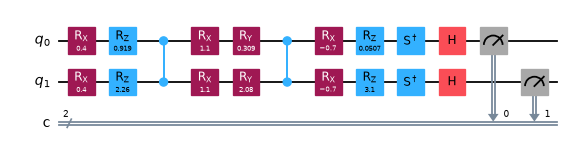

In [16]:
if HAVE_AER:
    from qiskit import QuantumCircuit
    from qiskit.quantum_info import Statevector, SparsePauliOp
    from qiskit_aer import AerSimulator
    from qiskit_aer.noise import NoiseModel, depolarizing_error

    def qiskit_circuit(ops, x, w, measure=True):
        """The same gate list as a Qiskit circuit; <sigma_y> is measured by S^dagger, H, then a computational-basis measurement."""
        qc = QuantumCircuit(2, 2 if measure else 0)
        for g, wire, src in ops:
            if g == "CZ":
                qc.cz(0, 1); continue
            ang = float(x[src[1]]) if src[0] == "x" else float(w[src[1]])
            getattr(qc, g.lower())(ang, wire)
        if measure:
            for q in range(2):
                qc.sdg(q); qc.h(q)
            qc.measure([0, 1], [0, 1])
        return qc

    # exact equivalence check: Qiskit statevector <Y_q> == PennyLane/PyTorch simulator (little-endian labels: 'IY' = Y on qubit 0)
    ops6, nw6 = circuit_spec(6)
    xs, ws = torch.randn(5, 3, dtype=torch.float64), torch.rand(nw6, dtype=torch.float64) * 6.28
    mine = run_spec(ops6, xs, ws)
    for b in range(5):
        sv = Statevector(qiskit_circuit(ops6, xs[b], ws, measure=False))
        e = [sv.expectation_value(SparsePauliOp(lbl)).real for lbl in ("IY", "YI")]
        assert abs(e[0] - mine[b, 0].item()) < 1e-10 and abs(e[1] - mine[b, 1].item()) < 1e-10
    print("Qiskit statevector <sigma_y> == PyTorch simulator == PennyLane (|diff| < 1e-10) for circuit 6")
    qc = qiskit_circuit(ops6, x_demo, w_demo[:6], measure=True)
    print("Qiskit circuit executed by Aer: qubits =", qc.num_qubits, "| depth (with the basis-change + measurement layer) =", qc.depth(),
          "| gate counts =", dict(qc.count_ops()))
    from IPython.display import display
    fig = qc.draw("mpl", fold=-1, scale=0.8); display(fig)      # (Qiskit closes its figure under the inline backend, so display it explicitly)
else:
    print("Qiskit/Aer not installed: noisy-simulator circuit not drawn (section 5 will be skipped).")


## 3. Single client: HQSL against its classical twin (Fig. 7, Table 5)

For every dataset and every cross-validation fold we train the split model with the quantum layer (HQSL) and its classical twin (SL, `Linear(3 -> 2) + ReLU` instead of the circuit) from identical classical initial weights
and record test accuracy and macro-F1. Confusion matrices (positive class of the binary tasks = label 1) and the learned smashed angles are drawn for fold 0. We also report two ordinary scikit-learn baselines on the full feature vector.

In [17]:
MODELS = {}            # (dataset, fold, "HQSL"/"SL") -> (client, server)   (kept for the privacy experiments of section 7)
HIST0 = {}             # loss curves of fold 0
single_rows = []
t_all = time.time()
for name, d in DATASETS.items():
    for f, (tr, te) in enumerate(FOLDS[name]):
        Xtr, ytr, Xte, yte = fold_tensors(name, tr, te)
        for setting, quantum in (("SL", False), ("HQSL", True)):
            cl, sv = make_pair(name, quantum, seed=SEED + f)
            t0 = time.time()
            hist = train_split(cl, sv, Xtr, ytr, d["kind"], d["epochs"], LR[name], seed=SEED + f)
            acc, f1 = score(cl, sv, Xte, yte, d["kind"])
            MODELS[(name, f, setting)] = (cl, sv)
            if f == 0: HIST0[(name, setting)] = hist
            single_rows.append(dict(dataset=name, fold=f, setting=setting, accuracy=acc, f1=f1, final_loss=hist[-1], seconds=time.time() - t0))
        print(f"{name:16s} fold {f}: " + " | ".join(f"{r['setting']} acc {r['accuracy']:.3f} F1 {r['f1']:.3f} ({r['seconds']:.0f}s)" for r in single_rows[-2:]), flush=True)
single_df = pd.DataFrame(single_rows)
print(f"\nsection 3 finished in {(time.time() - t_all) / 60:.1f} min")

summary = (single_df.groupby(["dataset", "setting"], sort=False)[["accuracy", "f1"]].agg(["mean", "std"]).round(4))
print(summary.to_string())


Botnet DGA       fold 0: SL acc 0.934 F1 0.934 (12s) | HQSL acc 0.919 F1 0.919 (17s)


Botnet DGA       fold 1: SL acc 0.931 F1 0.931 (8s) | HQSL acc 0.946 F1 0.946 (21s)


Botnet DGA       fold 2: SL acc 0.937 F1 0.937 (7s) | HQSL acc 0.943 F1 0.943 (14s)


Breast Cancer    fold 0: SL acc 0.626 F1 0.385 (3s) | HQSL acc 0.979 F1 0.978 (9s)


Breast Cancer    fold 1: SL acc 0.937 F1 0.930 (4s) | HQSL acc 0.942 F1 0.936 (10s)


...

Speech Commands  fold 0: SL acc 0.922 F1 0.922 (29s) | HQSL acc 0.918 F1 0.918 (38s)


Speech Commands  fold 1: SL acc 0.890 F1 0.890 (27s) | HQSL acc 0.922 F1 0.922 (34s)


Speech Commands  fold 2: SL acc 0.892 F1 0.891 (29s) | HQSL acc 0.916 F1 0.916 (34s)



section 3 finished in 13.3 min

                        accuracy              f1        
                            mean     std    mean     std
dataset         setting                                 
Botnet DGA      SL        0.9340  0.0030  0.9340  0.0030
                HQSL      0.9360  0.0147  0.9360  0.0147
Breast Cancer   SL        0.8385  0.1839  0.7551  0.3206
                HQSL      0.9613  0.0185  0.9582  0.0207
MNIST           SL        0.4593  0.1778  0.4039  0.1996
                HQSL      0.7080  0.1578  0.6788  0.1924
FMNIST          SL        0.5267  0.1120  0.4557  0.1387
                HQSL      0.6360  0.0661  0.6021  0.0822
Speech Commands SL        0.9013  0.0179  0.9010  0.0182
                HQSL      0.9187  0.0031  0.9185  0.0032


### Fig. 7: accuracy and F1 over the folds, gains, loss curves

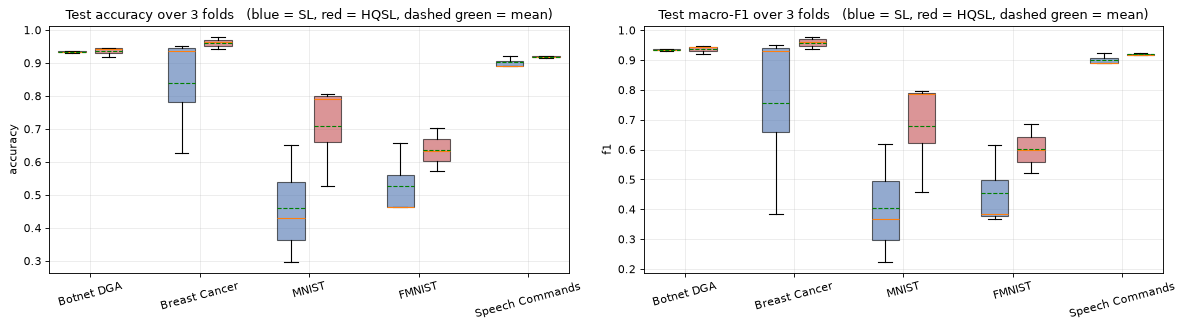

HQSL minus SL, percentage points (mean, std over folds):
                accuracy            f1       
                    mean    std   mean    std
dataset                                      
Botnet DGA          0.20   1.54   0.20   1.54
Breast Cancer      12.28  19.90  20.30  33.72
FMNIST             10.93   6.10  14.64   7.20
MNIST              24.87  22.58  27.48  25.84
Speech Commands     1.73   1.89   1.76   1.91


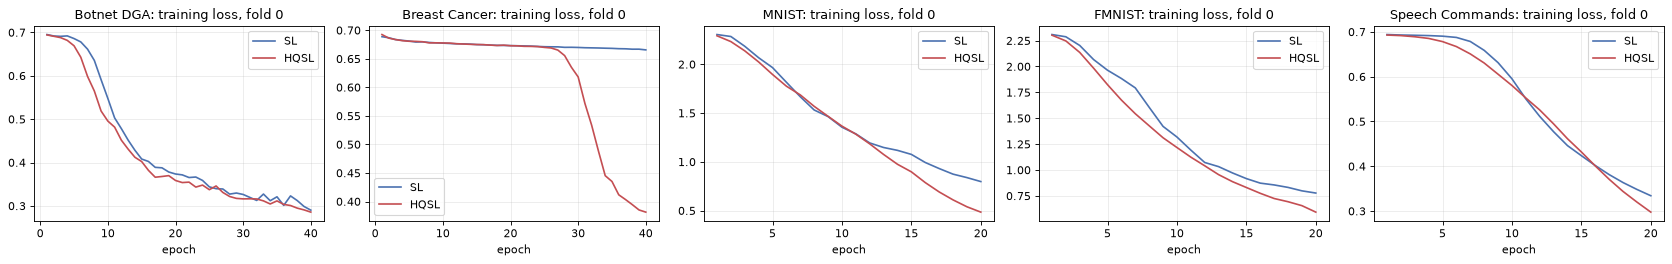

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.2))
for ax, metric, ttl in zip(axes, ["accuracy", "f1"], ["Test accuracy", "Test macro-F1"]):
    pos, data, cols, ticks = 0, [], [], []
    for name in DATASETS:
        for k, (setting, col) in enumerate((("SL", "#4C72B0"), ("HQSL", "#C44E52"))):
            vals = single_df[(single_df.dataset == name) & (single_df.setting == setting)][metric].values
            bp = ax.boxplot(vals, positions=[pos + k * 0.8], widths=0.6, patch_artist=True, showmeans=True, meanline=True,
                            meanprops=dict(color="green", ls="--"))
            bp["boxes"][0].set_facecolor(col); bp["boxes"][0].set_alpha(0.6)
        ticks.append(pos + 0.4); pos += 2.4
    ax.set_xticks(ticks); ax.set_xticklabels(DATASETS.keys(), rotation=15); ax.set_title(f"{ttl} over {N_FOLDS} folds   (blue = SL, red = HQSL, dashed green = mean)")
    ax.set_ylabel(metric)
plt.tight_layout(); plt.show()

# Fig. 7-style improvement of HQSL over SL, paired by fold, in percentage points
delta = single_df.pivot_table(index=["dataset", "fold"], columns="setting", values=["accuracy", "f1"])
imp = pd.DataFrame({m: (delta[(m, "HQSL")] - delta[(m, "SL")]) * 100 for m in ("accuracy", "f1")}).groupby("dataset", sort=False).agg(["mean", "std"]).round(2)
print("HQSL minus SL, percentage points (mean, std over folds):"); print(imp.to_string())

fig, axes = plt.subplots(1, 5, figsize=(21, 3.4))
for ax, name in zip(axes, DATASETS):
    for setting, col in (("SL", "#4C72B0"), ("HQSL", "#C44E52")):
        ax.plot(range(1, len(HIST0[(name, setting)]) + 1), HIST0[(name, setting)], color=col, label=setting)
    ax.set_title(f"{name}: training loss, fold 0"); ax.set_xlabel("epoch"); ax.legend()
plt.tight_layout(); plt.show()


### Confusion matrices and the learned smashed angles

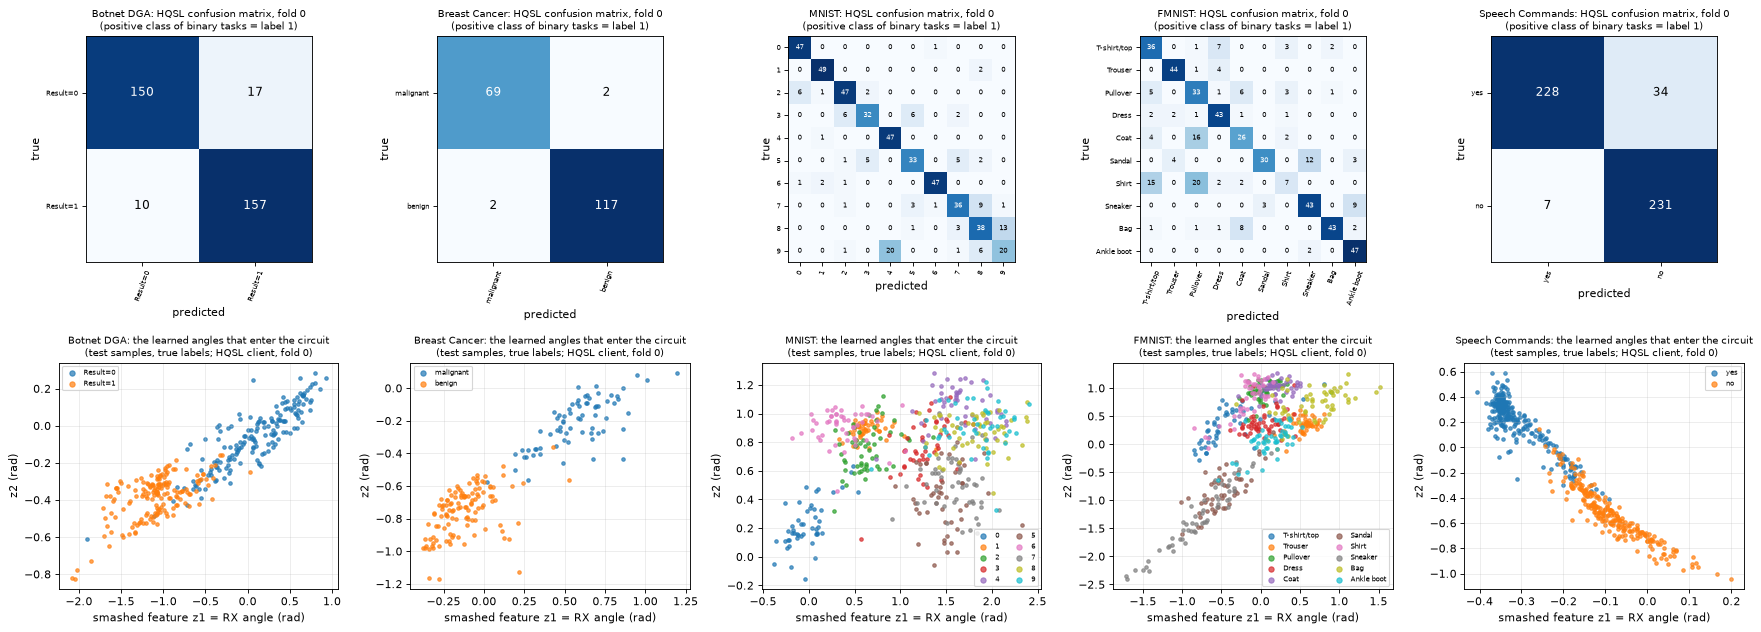

standard deviation of the smashed data z (fold 0, test): {'Botnet DGA': {'SL': 0.8, 'HQSL': 0.46}, 'Breast Cancer': {'SL': 0.32, 'HQSL': 0.53}, 'MNIST': {'SL': 9.99, 'HQSL': 1.31}, 'FMNIST': {'SL': 11.3, 'HQSL': 0.92}, 'Speech Commands': {'SL': 1.35, 'HQSL': 0.54}}


In [19]:
fig, axes = plt.subplots(2, 5, figsize=(22, 8))
for j, (name, d) in enumerate(DATASETS.items()):
    tr, te = FOLDS[name][0]
    Xtr, ytr, Xte, yte = fold_tensors(name, tr, te)
    cl, sv = MODELS[(name, 0, "HQSL")]
    out, Z = infer(cl, sv, Xte, d["kind"], return_z=True)
    pred = predict_labels(out, d["kind"]).numpy()
    cm = confusion_matrix(yte.numpy(), pred, labels=list(range(d["n_cls"])))
    ax = axes[0, j]; ax.imshow(cm, cmap="Blues"); ax.grid(False)
    for (i, k), v in np.ndenumerate(cm): ax.text(k, i, v, ha="center", va="center", fontsize=6 if d["n_cls"] == 10 else 11, color="k" if v < cm.max() / 2 else "w")
    ax.set_xticks(range(d["n_cls"])); ax.set_yticks(range(d["n_cls"]))
    ax.set_xticklabels(d["classes"], rotation=70, fontsize=6); ax.set_yticklabels(d["classes"], fontsize=6)
    ax.set_xlabel("predicted"); ax.set_ylabel("true"); ax.set_title(f"{name}: HQSL confusion matrix, fold 0\n(positive class of binary tasks = label 1)", fontsize=9)
    ax = axes[1, j]; Z = Z.numpy()
    for c in range(d["n_cls"]):
        ax.scatter(Z[yte.numpy() == c, 0], Z[yte.numpy() == c, 1], s=10, alpha=0.7, color=plt.get_cmap("tab10")(c), label=d["classes"][c])
    ax.set_xlabel("smashed feature z1 = RX angle (rad)"); ax.set_ylabel("z2 (rad)")
    ax.set_title(f"{name}: the learned angles that enter the circuit\n(test samples, true labels; HQSL client, fold 0)", fontsize=9)
    if d["n_cls"] <= 10: ax.legend(fontsize=6, markerscale=1.5, ncol=2 if d["n_cls"] > 2 else 1)
plt.tight_layout(); plt.show()
Z_SCALE = {}
for name, d in DATASETS.items():
    tr, te = FOLDS[name][0]; _, _, Xte, yte = fold_tensors(name, tr, te)
    Z_SCALE[name] = {s: float(infer(*MODELS[(name, 0, s)], Xte, d["kind"], return_z=True)[1].std()) for s in ("SL", "HQSL")}
print("standard deviation of the smashed data z (fold 0, test):", {k: {s: round(v, 2) for s, v in dd.items()} for k, dd in Z_SCALE.items()})


### Extra classical baselines (RandomForest, SVC) on the whole feature vector

In [20]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
# Extra classical baselines (not in the paper): trained on the whole feature vector of each fold (7 features / 784 pixels),
# i.e. WITHOUT the split and without the 3-dimensional bottleneck, so they show what the data allow in principle.
base_rows = []
t0 = time.time()
for name, d in DATASETS.items():
    for f, (tr, te) in enumerate(FOLDS[name]):
        Xtr, ytr, Xte, yte = fold_tensors(name, tr, te)
        A, B = Xtr.flatten(1).numpy(), Xte.flatten(1).numpy()
        for mname, mdl in (("RandomForest", RandomForestClassifier(n_estimators=100, random_state=SEED, n_jobs=1)),
                           ("SVC(rbf)", SVC(kernel="rbf", C=1.0, gamma="scale"))):
            p = mdl.fit(A, ytr.numpy()).predict(B)
            base_rows.append(dict(dataset=name, model=mname, fold=f, accuracy=accuracy_score(yte.numpy(), p), f1=f1_score(yte.numpy(), p, average="macro")))
base_df = pd.DataFrame(base_rows)
tab = base_df.groupby(["dataset", "model"], sort=False)[["accuracy", "f1"]].agg(["mean", "std"]).round(4)
print(tab.to_string()); print(f"({time.time() - t0:.0f}s)")


                             accuracy              f1        
                                 mean     std    mean     std
dataset         model                                        
Botnet DGA      RandomForest   0.9340  0.0080  0.9340  0.0080
                SVC(rbf)       0.9200  0.0125  0.9199  0.0125
Breast Cancer   RandomForest   0.9490  0.0343  0.9448  0.0380
                SVC(rbf)       0.9561  0.0270  0.9520  0.0305
MNIST           RandomForest   0.9100  0.0171  0.9091  0.0190
                SVC(rbf)       0.9267  0.0129  0.9265  0.0142
FMNIST          RandomForest   0.7987  0.0179  0.7900  0.0188
                SVC(rbf)       0.8000  0.0151  0.7923  0.0150
Speech Commands RandomForest   0.9393  0.0042  0.9392  0.0042
                SVC(rbf)       0.9587  0.0127  0.9586  0.0127
(71s)


## 4. Which circuit? (Table 2, Fashion-MNIST)

Circuits 7, 8, 6, 9, 10 are trained as the quantum layer of HQSL on Fashion-MNIST with the same data folds, and compared with the classical twin. The resource columns (parameters, depth) were already asserted in the circuit section.

fold 0 done (125s)


fold 1 done (242s)


Fashion-MNIST, HQSL with each circuit (2 folds x 10 epochs) and the classical twin (SL):
        params depth paper acc paper F1    notebook acc     notebook F1
circuit                                                                
7            6     6     0.812    0.815  0.487 +- 0.123  0.401 +- 0.128
8            6     8     0.823    0.825  0.321 +- 0.086  0.205 +- 0.082
6            6     8     0.839     0.84  0.517 +- 0.013  0.451 +- 0.015
9           18    20     0.824    0.826  0.393 +- 0.098  0.270 +- 0.106
10          18    18     0.821    0.823  0.399 +- 0.214  0.291 +- 0.232
SL           -     -         -        -  0.460 +- 0.076  0.401 +- 0.113


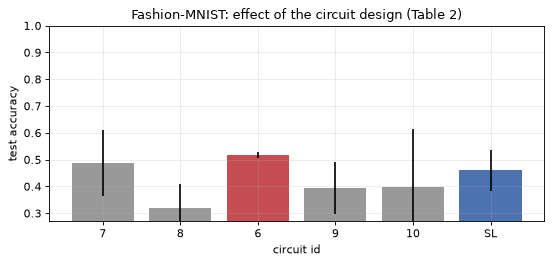

In [21]:
name = "FMNIST"; d = DATASETS[name]
circ_rows = []
t0 = time.time()
for f, (tr, te) in enumerate(FOLDS[name][:CIRC_FOLDS]):
    Xtr, ytr, Xte, yte = fold_tensors(name, tr, te)
    for cid in (7, 8, 6, 9, 10):
        cl, sv = make_pair(name, True, seed=SEED + f, cid=cid)
        train_split(cl, sv, Xtr, ytr, d["kind"], CIRC_EPOCHS, LR[name], seed=SEED + f)
        acc, f1 = score(cl, sv, Xte, yte, d["kind"])
        circ_rows.append(dict(circuit=cid, fold=f, accuracy=acc, f1=f1))
    cl, sv = make_pair(name, False, seed=SEED + f)
    train_split(cl, sv, Xtr, ytr, d["kind"], CIRC_EPOCHS, LR[name], seed=SEED + f)
    acc, f1 = score(cl, sv, Xte, yte, d["kind"]); circ_rows.append(dict(circuit="SL", fold=f, accuracy=acc, f1=f1))
    print(f"fold {f} done ({time.time() - t0:.0f}s)", flush=True)
circ_df = pd.DataFrame(circ_rows)
g = circ_df.groupby("circuit", sort=False)[["accuracy", "f1"]].agg(["mean", "std"])
tbl = pd.DataFrame({
    "params": [PAPER_TABLE2[c][0] if c != "SL" else "-" for c in g.index],
    "depth": [PAPER_TABLE2[c][1] if c != "SL" else "-" for c in g.index],
    "paper acc": [PAPER_TABLE2[c][2] if c != "SL" else "-" for c in g.index],
    "paper F1": [PAPER_TABLE2[c][3] if c != "SL" else "-" for c in g.index],
    "notebook acc": [f"{g.loc[c, ('accuracy', 'mean')]:.3f} +- {g.loc[c, ('accuracy', 'std')]:.3f}" for c in g.index],
    "notebook F1": [f"{g.loc[c, ('f1', 'mean')]:.3f} +- {g.loc[c, ('f1', 'std')]:.3f}" for c in g.index]}, index=g.index)
print(f"Fashion-MNIST, HQSL with each circuit ({CIRC_FOLDS} folds x {CIRC_EPOCHS} epochs) and the classical twin (SL):")
print(tbl.to_string())
fig, ax = plt.subplots(figsize=(7, 3.4))
order = [c for c in g.index]
ax.bar([str(c) for c in order], [g.loc[c, ("accuracy", "mean")] for c in order], yerr=[g.loc[c, ("accuracy", "std")] for c in order],
       color=["#C44E52" if c == 6 else ("#4C72B0" if c == "SL" else "#999999") for c in order])
ax.set_ylim(min(0.6, g[("accuracy", "mean")].min() - 0.05), 1); ax.set_xlabel("circuit id"); ax.set_ylabel("test accuracy"); ax.set_title("Fashion-MNIST: effect of the circuit design (Table 2)")
plt.tight_layout(); plt.show()


## 5. Noisy simulators and hardware (Fig. 8)

As in the paper the model is **trained on the exact simulator** and only *evaluated* on other back-ends: the quantum layer's expectation values are re-estimated with 1000 shots on Qiskit-Aer, with single- and two-qubit depolarising noise of strength p on every gate,
and fed to the same classical head. The paper additionally used three real IBM devices, which cannot be repeated here (see the table of choices).

max |Aer ideal (1000 shots) - exact expectation| : 0.081  (shot noise ~ 1/sqrt(1000) = 0.03)


p = 0.05: mean |<Y>| attenuation vs exact = 0.53


p = 0.075: mean |<Y>| attenuation vs exact = 0.38


p = 0.08: mean |<Y>| attenuation vs exact = 0.35


p = 0.09: mean |<Y>| attenuation vs exact = 0.31


p = 0.05 (native sx/x/cx noise): mean |<Y>| attenuation vs exact = 0.58


p = 0.075 (native sx/x/cx noise): mean |<Y>| attenuation vs exact = 0.44


p = 0.08 (native sx/x/cx noise): mean |<Y>| attenuation vs exact = 0.42


p = 0.09 (native sx/x/cx noise): mean |<Y>| attenuation vs exact = 0.37


Aer runs: 40s
IBM_TOKEN is empty -> real-hardware evaluation skipped (cannot be reproduced here).
                               backend  accuracy    f1 paper accuracy paper F1
                         default.qubit      0.90 0.899           0.92    0.904
          qiskit_aer ideal, 1000 shots      0.90 0.899              -        -
                     qiskit_aer p=0.05      0.93 0.929           0.89    0.861
                    qiskit_aer p=0.075      0.92 0.919           0.83    0.767
                     qiskit_aer p=0.08      0.92 0.919           0.72    0.548
                     qiskit_aer p=0.09      0.93 0.929            0.6      0.2
 qiskit_aer p=0.05 (native-gate noise)      0.92 0.919              -        -
qiskit_aer p=0.075 (native-gate noise)      0.92 0.919              -        -
 qiskit_aer p=0.08 (native-gate noise)      0.93 0.929              -        -
 qiskit_aer p=0.09 (native-gate noise)      0.92 0.919              -        -


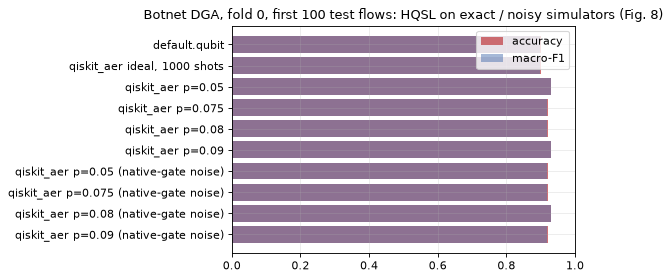

In [22]:
PAPER_FIG8 = {   # Fig. 8, Botnet DGA, one fold: backend -> (accuracy, F1)
    "default.qubit": (0.920, 0.904), "ibm_sherbrooke": (0.915, 0.897), "ibm_strasbourg": (0.915, 0.896), "ibm_brussels": (0.920, 0.904),
    "qiskit_aer p=0.05": (0.890, 0.861), "qiskit_aer p=0.075": (0.830, 0.767), "qiskit_aer p=0.08": (0.720, 0.548), "qiskit_aer p=0.09": (0.600, 0.200)}

name = "Botnet DGA"; d = DATASETS[name]
tr, te = FOLDS[name][0]
Xtr, ytr, Xte, yte = fold_tensors(name, tr, te)
cl, sv = MODELS[(name, 0, "HQSL")]                      # trained on the noise-free exact simulator (the paper's default.qubit), fold 0
cl.eval(); sv.eval()
with torch.no_grad():
    Zte = cl(Xte[:NOISY_TEST_N])                         # smashed data of the client (classical, noise-free)
y_te = yte[:NOISY_TEST_N].numpy()
qlayer, head = sv[0], sv[1]
W = qlayer.weights.detach()

def head_scores(E):
    with torch.no_grad():
        pred = predict_labels(head(torch.as_tensor(E, dtype=torch.float32)), d["kind"]).numpy()
    return accuracy_score(y_te, pred), f1_score(y_te, pred, average="macro")

noisy_rows = []
with torch.no_grad():
    E_exact = qlayer(Zte).numpy()
a, f = head_scores(E_exact); noisy_rows.append(dict(backend="default.qubit", accuracy=a, f1=f))

def aer_expectations(Z, noise_p=None, shots=SHOTS, seed=SEED, hw_basis=False):
    """<sigma_y> of both qubits for every smashed vector, measured with `shots` shots on Qiskit-Aer.
    hw_basis=False: depolarising noise on every LOGICAL gate (rx, ry, rz, sdg, h; cz).
    hw_basis=True : CHOICE (the paper does not say how the noise was attached) the circuits are first transpiled to an IBM-like basis
                    (rz, sx, x, cx; rz is virtual and noiseless) and the depolarising noise sits on sx / x (1 qubit) and cx (2 qubits)."""
    nm = None
    if noise_p is not None:
        nm = NoiseModel()
        one, two = (["sx", "x"], ["cx"]) if hw_basis else (["rx", "ry", "rz", "sdg", "h"], ["cz"])
        nm.add_all_qubit_quantum_error(depolarizing_error(noise_p, 1), one)
        nm.add_all_qubit_quantum_error(depolarizing_error(noise_p, 2), two)
    sim = AerSimulator(noise_model=nm, seed_simulator=seed)
    circuits = [qiskit_circuit(qlayer.ops, Z[i].numpy().astype(float), W.numpy(), measure=True) for i in range(len(Z))]
    if hw_basis:
        from qiskit import transpile
        circuits = transpile(circuits, basis_gates=["rz", "sx", "x", "cx"], optimization_level=1, seed_transpiler=seed)
    res = sim.run(circuits, shots=shots).result()
    E = np.zeros((len(Z), 2))
    for i in range(len(Z)):
        counts = res.get_counts(i)
        for q in range(2):                                # bit q of the key (little-endian): 0 -> +1, 1 -> -1
            n0 = sum(v for k_, v in counts.items() if k_[::-1][q] == "0"); E[i, q] = (2 * n0 - shots) / shots
    return E

if HAVE_AER:
    t0 = time.time()
    E_ideal = aer_expectations(Zte, None)
    print("max |Aer ideal (1000 shots) - exact expectation| :", np.abs(E_ideal - E_exact).max().round(3), " (shot noise ~ 1/sqrt(1000) = 0.03)")
    a, f = head_scores(E_ideal); noisy_rows.append(dict(backend="qiskit_aer ideal, 1000 shots", accuracy=a, f1=f))
    for p in DEPOL_P:
        E_p = aer_expectations(Zte, p)
        a, f = head_scores(E_p); noisy_rows.append(dict(backend=f"qiskit_aer p={p}", accuracy=a, f1=f))
        print(f"p = {p}: mean |<Y>| attenuation vs exact = {np.abs(E_p).mean() / np.abs(E_exact).mean():.2f}", flush=True)
    for p in DEPOL_P:                                    # second noise placement: IBM-like native gates
        E_p = aer_expectations(Zte, p, hw_basis=True)
        a, f = head_scores(E_p); noisy_rows.append(dict(backend=f"qiskit_aer p={p} (native-gate noise)", accuracy=a, f1=f))
        print(f"p = {p} (native sx/x/cx noise): mean |<Y>| attenuation vs exact = {np.abs(E_p).mean() / np.abs(E_exact).mean():.2f}", flush=True)
    print(f"Aer runs: {time.time() - t0:.0f}s")
else:
    print("Aer not available -> noisy simulators skipped")

# real hardware: only if the reader supplies an IBM Quantum token (the paper used ibm_sherbrooke / ibm_strasbourg / ibm_brussels)
if IBM_TOKEN:
    try:
        from qiskit import transpile
        from qiskit_ibm_runtime import QiskitRuntimeService, SamplerV2
        service = QiskitRuntimeService(channel="ibm_quantum_platform", token=IBM_TOKEN)
        backend = service.least_busy(operational=True, simulator=False, min_num_qubits=2)
        circs = [transpile(qiskit_circuit(qlayer.ops, Zte[i].numpy().astype(float), W.numpy()), backend, optimization_level=1) for i in range(len(Zte))]
        job = SamplerV2(mode=backend).run(circs, shots=SHOTS); print("submitted to", backend.name, "- poll job", job.job_id())
    except Exception as e:                       # not exercised in this notebook run (IBM_TOKEN is empty)
        print("hardware run failed:", e)
else:
    print("IBM_TOKEN is empty -> real-hardware evaluation skipped (cannot be reproduced here).")

noisy_df = pd.DataFrame(noisy_rows).round(3)
paper_col = [PAPER_FIG8.get(b, ("-", "-")) for b in noisy_df.backend]
noisy_df["paper accuracy"] = [p[0] for p in paper_col]; noisy_df["paper F1"] = [p[1] for p in paper_col]
print(noisy_df.to_string(index=False))
fig, ax = plt.subplots(figsize=(7.5, 3.6))
ax.barh(noisy_df.backend[::-1], noisy_df.accuracy[::-1], color="#C44E52", alpha=0.8, label="accuracy"); ax.barh(noisy_df.backend[::-1], noisy_df.f1[::-1], color="#4C72B0", alpha=0.5, label="macro-F1")
ax.set_xlim(0, 1); ax.legend(); ax.set_title(f"Botnet DGA, fold 0, first {NOISY_TEST_N} test flows: HQSL on exact / noisy simulators (Fig. 8)")
plt.tight_layout(); plt.show()


## 6. Many clients (Fig. 9)

The training set is cut into K random, equally sized (IID) client shards and Algorithm 2 is run: clients are served in turn, each performing one local epoch, and the client weights are handed to the next client. After the last global epoch the model is tested on the held-out fold (one fold only, like the paper).

Botnet DGA       K=  2: SL acc 0.829 F1 0.827 | HQSL acc 0.823 F1 0.821   (6s)


Botnet DGA       K= 10: SL acc 0.850 F1 0.850 | HQSL acc 0.835 F1 0.834   (19s)


Botnet DGA       K=100: SL acc 0.940 F1 0.940 | HQSL acc 0.934 F1 0.934   (77s)


Breast Cancer    K=  2: SL acc 0.626 F1 0.385 | HQSL acc 0.626 F1 0.385   (81s)


Breast Cancer    K= 10: SL acc 0.626 F1 0.385 | HQSL acc 0.626 F1 0.385   (88s)


...

FMNIST           K= 10: SL acc 0.368 F1 0.275 | HQSL acc 0.390 F1 0.265   (324s)


FMNIST           K=100: SL acc 0.522 F1 0.437 | HQSL acc 0.674 F1 0.626   (378s)


Speech Commands  K=  2: SL acc 0.524 F1 0.344 | HQSL acc 0.524 F1 0.344   (410s)


Speech Commands  K= 10: SL acc 0.524 F1 0.344 | HQSL acc 0.524 F1 0.344   (433s)


Speech Commands  K=100: SL acc 0.930 F1 0.930 | HQSL acc 0.944 F1 0.944   (479s)


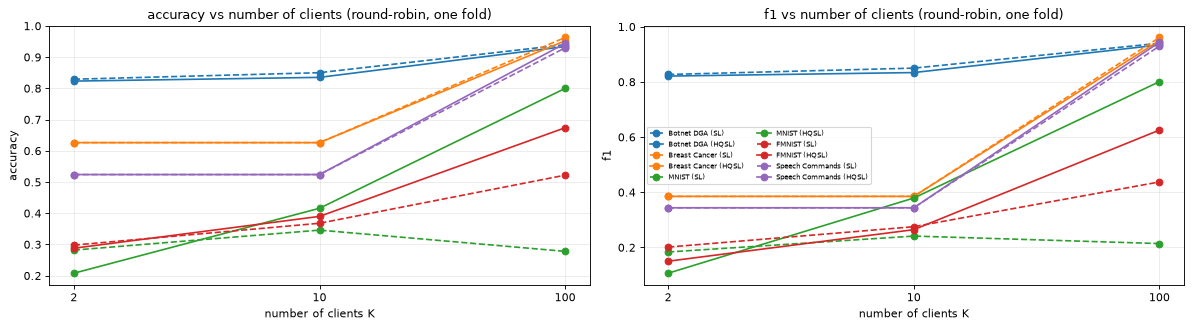

K                          2      10     100
dataset         setting                     
Botnet DGA      SL       0.829  0.850  0.940
                HQSL     0.823  0.835  0.934
Breast Cancer   SL       0.626  0.626  0.963
                HQSL     0.626  0.626  0.953
MNIST           SL       0.282  0.346  0.278
                HQSL     0.208  0.416  0.800
FMNIST          SL       0.298  0.368  0.522
                HQSL     0.288  0.390  0.674
Speech Commands SL       0.524  0.524  0.930
                HQSL     0.524  0.524  0.944


In [23]:
def iid_shards(n, K, seed):
    """Split the training indices into K independent, identically distributed (random, equal-size) client shards."""
    perm = np.random.default_rng(seed).permutation(n)
    return [s for s in np.array_split(perm, K)]

mc_rows = []
t0 = time.time()
for name, d in DATASETS.items():
    tr, te = FOLDS[name][0]
    Xtr, ytr, Xte, yte = fold_tensors(name, tr, te)
    ep = MC_EPOCHS["tab" if d["kind"] == "tab" else "img"]
    for K in MC_K:
        shards = iid_shards(len(Xtr), K, SEED)
        for setting, quantum in (("SL", False), ("HQSL", True)):
            cl, sv = make_pair(name, quantum, seed=SEED)
            train_split(cl, sv, Xtr, ytr, d["kind"], ep, LR[name], shards=shards, seed=SEED)
            acc, f1 = score(cl, sv, Xte, yte, d["kind"])
            mc_rows.append(dict(dataset=name, K=K, setting=setting, accuracy=acc, f1=f1))
        print(f"{name:16s} K={K:3d}: " + " | ".join(f"{r['setting']} acc {r['accuracy']:.3f} F1 {r['f1']:.3f}" for r in mc_rows[-2:]) + f"   ({time.time() - t0:.0f}s)", flush=True)
mc_df = pd.DataFrame(mc_rows)

fig, axes = plt.subplots(1, 2, figsize=(15, 4.2))
for ax, metric in zip(axes, ["accuracy", "f1"]):
    for k, name in enumerate(DATASETS):
        for setting, ls in (("SL", "--"), ("HQSL", "-")):
            s = mc_df[(mc_df.dataset == name) & (mc_df.setting == setting)]
            ax.plot(range(len(s)), s[metric].values, ls, marker="o", color=plt.get_cmap("tab10")(k), label=f"{name} ({setting})")
    ax.set_xticks(range(len(MC_K))); ax.set_xticklabels(MC_K); ax.set_xlabel("number of clients K"); ax.set_ylabel(metric)
    ax.set_title(f"{metric} vs number of clients (round-robin, one fold)")
axes[1].legend(fontsize=6, ncol=2)
plt.tight_layout(); plt.show()
print(mc_df.pivot_table(index=["dataset", "setting"], columns="K", values="accuracy", sort=False).round(3).to_string())


## 7. Reconstruction attack and the Laplace-noise defence (Sec. 6, Figs. 13-16, Tables 6-7)

**Attack.** The honest-but-curious server owns auxiliary data `X_rec` (4/5 of the test fold) and uses the client model as its shadow model to obtain smashed data `Z_rec`; it trains a decoder `Z -> image` (three architectures) and applies it to the smashed data
of the disjoint private images `X_inf` (the remaining 1/5). **Defence.** Before sending, the client adds Laplace(mu, b) noise to the smashed data. We measure how far the reconstruction is from the original (cosine distance, MSE, DSSIM, LSD for spectrograms - larger means better privacy)
and how the noise affects the server's classification accuracy (Figs. 14-15), for mu in {0, pi, 2 pi, 3 pi, 4 pi} and b in {0.01, 0.1, 0.5, 1}. `RX` has period 4 pi, so mu = 2 pi k leaves the quantum layer's input state (almost) unchanged for small b.
The last cells add something the paper does not test: an attacker who simply re-centres the received smashed data.

### Attack models, metrics and the noise sweep

In [24]:
class ResBlock(nn.Module):
    def __init__(self, c):
        super().__init__()
        self.a, self.b = nn.Conv2d(c, c, 3, padding=1), nn.BatchNorm2d(c)
        self.c, self.d = nn.Conv2d(c, c, 3, padding=1), nn.BatchNorm2d(c)
    def forward(self, x):
        return F.relu(x + self.d(self.c(F.relu(self.b(self.a(x))))))

class Recon1(nn.Module):
    """Reconstruction model 1 (after Vepakomma et al. 2020, feature inversion): transposed convolutions with ResNet-style skip
    connections, ReLU and batch-norm; 3-dimensional smashed data -> 28 x 28 image.  CHOICE: widths 32/16/8 (not given in the paper)."""
    def __init__(self):
        super().__init__()
        self.fc, self.bn0 = nn.Linear(SMASHED_DIM, 32 * 7 * 7), nn.BatchNorm2d(32)
        self.r1, self.up1, self.bn1 = ResBlock(32), nn.ConvTranspose2d(32, 16, 4, 2, 1), nn.BatchNorm2d(16)
        self.r2, self.up2, self.bn2 = ResBlock(16), nn.ConvTranspose2d(16, 8, 4, 2, 1), nn.BatchNorm2d(8)
        self.out = nn.Conv2d(8, 1, 3, padding=1)
    def forward(self, z):
        h = F.relu(self.bn0(self.fc(z).view(-1, 32, 7, 7))); h = self.r1(h)
        h = self.r2(F.relu(self.bn1(self.up1(h)))); h = F.relu(self.bn2(self.up2(h)))
        return self.out(h)

class Recon2(nn.Module):
    """Reconstruction model 2: decoder half of the fully convolutional auto-encoder of Li et al. 2018 (upsampling + deconvolutions,
    ReLU, batch-norm after every deconvolution except the last).  CHOICE: widths 32/16/1."""
    def __init__(self):
        super().__init__()
        self.fc = nn.Linear(SMASHED_DIM, 32 * 7 * 7)
        self.d1, self.bn1 = nn.ConvTranspose2d(32, 16, 3, 1, 1), nn.BatchNorm2d(16)
        self.d2 = nn.ConvTranspose2d(16, 1, 3, 1, 1)
    def forward(self, z):
        h = F.relu(self.fc(z)).view(-1, 32, 7, 7)
        h = F.relu(self.bn1(self.d1(F.interpolate(h, scale_factor=2))))
        return self.d2(F.interpolate(h, scale_factor=2))

class Recon3(nn.Module):
    """Reconstruction model 3: fully connected decoder of Balle et al. 2022, two hidden layers of width 1000."""
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(SMASHED_DIM, 1000), nn.ReLU(), nn.Linear(1000, 1000), nn.ReLU(), nn.Linear(1000, 784))
    def forward(self, z):
        return self.net(z).view(-1, 1, 28, 28)

def train_recon(mid, Z, X, epochs, seed=SEED, bs=32):
    """Attacker training on (smashed data, image) pairs of the auxiliary set.  Paper: model 1 SGD(1e-3, 0.9) + L1, 200 epochs;
    model 2 Adam 1e-3 + MSE; model 3 RMSprop 1e-3 + (L1 + MSE)."""
    torch.manual_seed(seed)
    net = {1: Recon1, 2: Recon2, 3: Recon3}[mid]()
    opt = {1: lambda p: torch.optim.SGD(p, lr=1e-3, momentum=0.9), 2: lambda p: torch.optim.Adam(p, lr=1e-3),
           3: lambda p: torch.optim.RMSprop(p, lr=1e-3)}[mid](net.parameters())
    crit = {1: lambda a, b: F.l1_loss(a, b), 2: lambda a, b: F.mse_loss(a, b), 3: lambda a, b: F.l1_loss(a, b) + F.mse_loss(a, b)}[mid]
    g = torch.Generator().manual_seed(seed)
    for ep in range(epochs):
        net.train()
        perm = torch.randperm(len(Z), generator=g)
        for i in range(0, len(perm), bs):
            idx = perm[i:i + bs]
            if len(idx) < 2: continue
            opt.zero_grad(); crit(net(Z[idx]), X[idx]).backward(); opt.step()
    return net.eval()

# ---- image-comparison metrics of Appendix D ---------------------------------------------------
_g1 = torch.exp(-(torch.arange(11) - 5.0) ** 2 / (2 * 1.5 ** 2)); _g1 = _g1 / _g1.sum()
_WIN = (_g1[:, None] * _g1[None, :])[None, None].double()

def ssim_batch(A, B, L=1.0):
    """Mean structural similarity per image (Gaussian 11x11 window, sigma 1.5, data range L)."""
    c = lambda t: F.conv2d(t, _WIN)
    ma, mb = c(A), c(B); saa, sbb, sab = c(A * A) - ma ** 2, c(B * B) - mb ** 2, c(A * B) - ma * mb
    C1, C2 = (0.01 * L) ** 2, (0.03 * L) ** 2
    return (((2 * ma * mb + C1) * (2 * sab + C2)) / ((ma ** 2 + mb ** 2 + C1) * (saa + sbb + C2))).mean((1, 2, 3))

def recon_metrics(A, B):
    """A = original images, B = reconstructions, both [N, 1, 28, 28].  Masked as in the paper (pixels where at least one image is non-zero).
    Returns mean cosine distance, mean MSE, mean DSSIM and mean log-spectral distance (LSD is meaningful for the spectrograms only)."""
    A, B = A.double(), B.double()
    m = ((A != 0) | (B != 0)).double(); Am, Bm = (A * m).flatten(1), (B * m).flatten(1)
    cos = 1 - (Am * Bm).sum(1) / (Am.norm(dim=1) * Bm.norm(dim=1) + 1e-12)
    mse = (((A - B) * m) ** 2).flatten(1).sum(1) / m.flatten(1).sum(1).clamp(min=1)
    ssim = ssim_batch(A, B).clamp(min=0)
    dssim = (1 - ssim) / 2                       # CHOICE: the paper's text says 0 <= DSSIM <= 0.5, i.e. (1 - SSIM)/2 with SSIM clipped at 0
    eps = 1e-3
    lsd = torch.sqrt((((torch.log10((A.abs() + eps) / (B.abs() + eps))) * m) ** 2).flatten(1).sum(1) / m.flatten(1).sum(1).clamp(min=1))
    return dict(cosine=cos.mean().item(), mse=mse.mean().item(), dssim=dssim.mean().item(), lsd=lsd.mean().item())

# sanity checks of the metrics on known cases
_x = torch.rand(8, 1, 28, 28)
mm = recon_metrics(_x, _x); assert mm["cosine"] < 1e-9 and mm["mse"] < 1e-12 and mm["dssim"] < 1e-9 and mm["lsd"] < 1e-9
mm2 = recon_metrics(_x, torch.rand(8, 1, 28, 28)); assert mm2["dssim"] > 0.3 and mm2["cosine"] > 0.1
print("metric sanity: identical images -> all distances 0; independent noise images -> DSSIM", round(mm2["dssim"], 3), "(max 0.5)")


metric sanity: identical images -> all distances 0; independent noise images -> DSSIM 0.481 (max 0.5)


In [25]:
IMG_SETS = ["MNIST", "FMNIST", "Speech Commands"]
ATT = {}          # dataset -> dict(Xrec, Xinf, Z_rec[setting], Z_inf[setting])
RECON = {}        # (dataset, setting, model id) -> trained attacker
t0 = time.time()
for name in IMG_SETS:
    d = DATASETS[name]
    tr, te = FOLDS[name][0]
    Xtr, ytr, Xte, yte = fold_tensors(name, tr, te)
    # paper Sec. 6.2: the test fold is split 4 : 1 into X_rec (auxiliary data of the attacker) and X_inf (private inference data), disjoint
    perm = torch.randperm(len(Xte), generator=torch.Generator().manual_seed(SEED)); n_rec = int(0.8 * len(Xte))
    Xrec, Xinf = Xte[perm[:n_rec]], Xte[perm[n_rec:]]
    ATT[name] = dict(Xrec=Xrec, Xinf=Xinf, yinf=yte[perm[n_rec:]], Z_rec={}, Z_inf={})
    for setting in ("SL", "HQSL"):
        cl, sv = MODELS[(name, 0, setting)]
        ATT[name]["Z_rec"][setting] = infer(cl, sv, Xrec, "img", return_z=True)[1]        # the client model acts as the attacker's shadow model
        ATT[name]["Z_inf"][setting] = infer(cl, sv, Xinf, "img", return_z=True)[1]
        mids = (1, 2, 3) if name in RECON_MODELS_2_3 else (1,)
        for mid in mids:
            RECON[(name, setting, mid)] = train_recon(mid, ATT[name]["Z_rec"][setting], Xrec, RECON_EPOCHS)
        print(f"{name:16s} {setting:4s}: attacker model(s) {mids} trained on {len(Xrec)} auxiliary samples ({time.time() - t0:.0f}s)", flush=True)

@torch.no_grad()
def attack(name, setting, mid, mu=None, b=None, seed=0, recentre=False):
    """Reconstruct X_inf from (possibly Laplace-perturbed) smashed data; returns the metrics dict."""
    Z = ATT[name]["Z_inf"][setting].clone()
    if mu is not None:
        Z = Z + laplace_noise(Z.shape, mu, b, torch.Generator().manual_seed(seed))
    if recentre:     # EXTENSION (not in the paper): the attacker removes the offset by matching medians with its own auxiliary smashed data
        Z = Z - (Z.median(0).values - ATT[name]["Z_rec"][setting].median(0).values)
    return recon_metrics(ATT[name]["Xinf"], RECON[(name, setting, mid)](Z))

sweep_rows = []
for name in IMG_SETS:
    for setting in ("SL", "HQSL"):
        sweep_rows.append(dict(dataset=name, setting=setting, mu="baseline", b="-", **attack(name, setting, 1)))
        for mu in NOISE_MU:
            for b in NOISE_B:
                sweep_rows.append(dict(dataset=name, setting=setting, mu=round(mu / np.pi), b=b, **attack(name, setting, 1, mu, b, seed=SEED)))
sweep_df = pd.DataFrame(sweep_rows)
base = sweep_df[sweep_df.mu == "baseline"].set_index(["dataset", "setting"])[["cosine", "mse", "dssim", "lsd"]]
print("noise-free baselines of the reconstruction attack (reconstruction model 1, X_inf):"); print(base.round(4).to_string())


MNIST            SL  : attacker model(s) (1,) trained on 400 auxiliary samples (36s)


MNIST            HQSL: attacker model(s) (1,) trained on 400 auxiliary samples (72s)


FMNIST           SL  : attacker model(s) (1, 2, 3) trained on 400 auxiliary samples (141s)


FMNIST           HQSL: attacker model(s) (1, 2, 3) trained on 400 auxiliary samples (213s)


Speech Commands  SL  : attacker model(s) (1,) trained on 400 auxiliary samples (252s)


Speech Commands  HQSL: attacker model(s) (1,) trained on 400 auxiliary samples (293s)


noise-free baselines of the reconstruction attack (reconstruction model 1, X_inf):
                         cosine     mse   dssim     lsd
dataset         setting                                
MNIST           SL       0.7373  0.1002  0.4639  1.3184
                HQSL     0.6146  0.0938  0.4704  1.3837
FMNIST          SL       0.2042  0.0787  0.4168  1.3742
                HQSL     0.2189  0.0835  0.4262  1.3580
Speech Commands SL       0.6025  0.0416  0.4261  0.9874
                HQSL     0.4861  0.0369  0.4480  0.9941


### Fig. 13 and Fig. 16: reconstruction error and reconstructed images

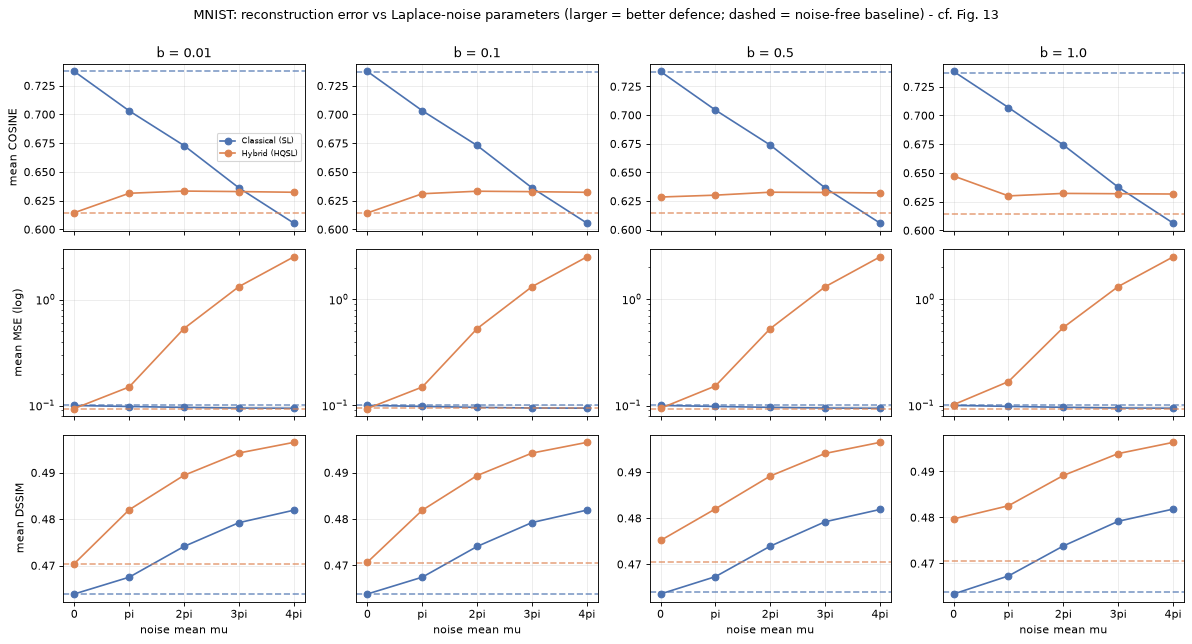

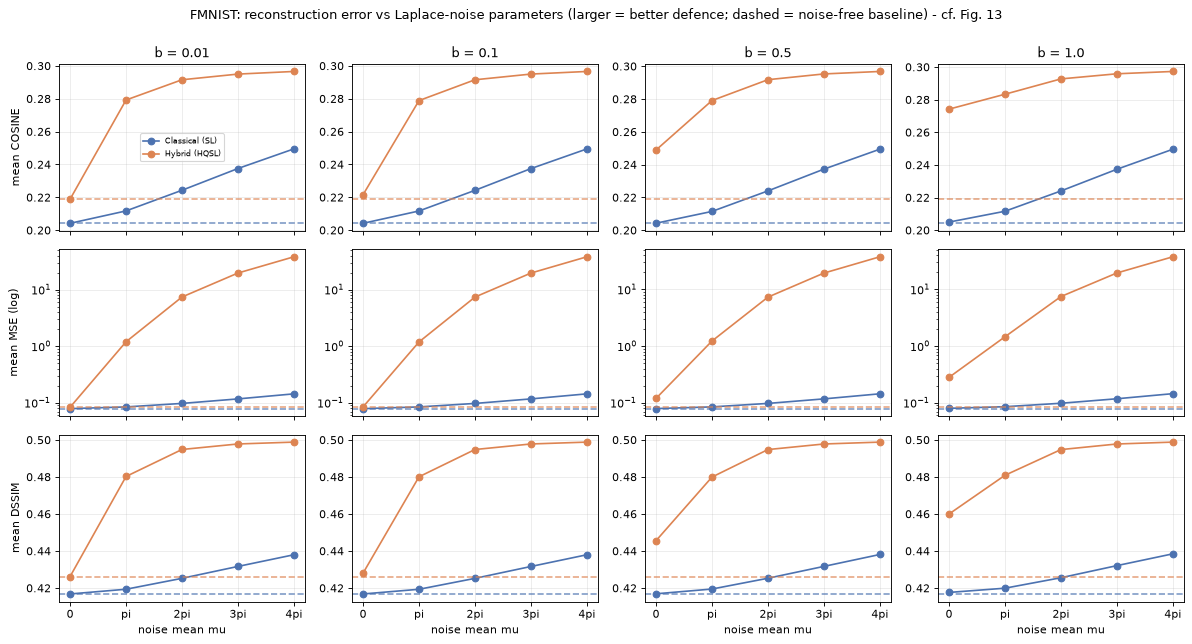

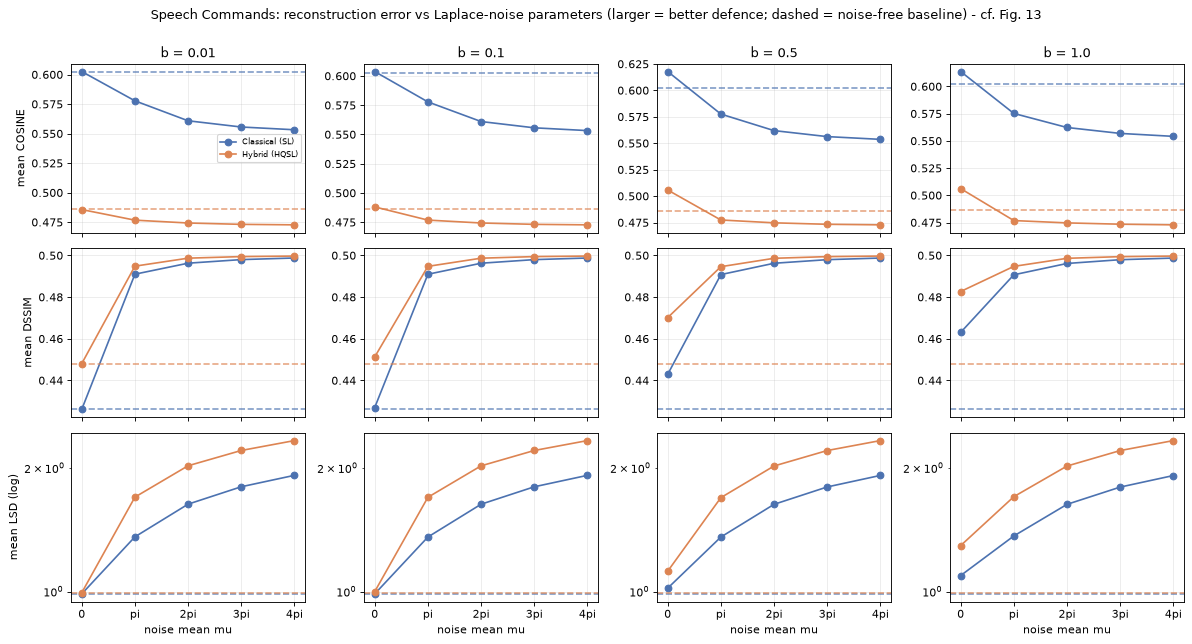

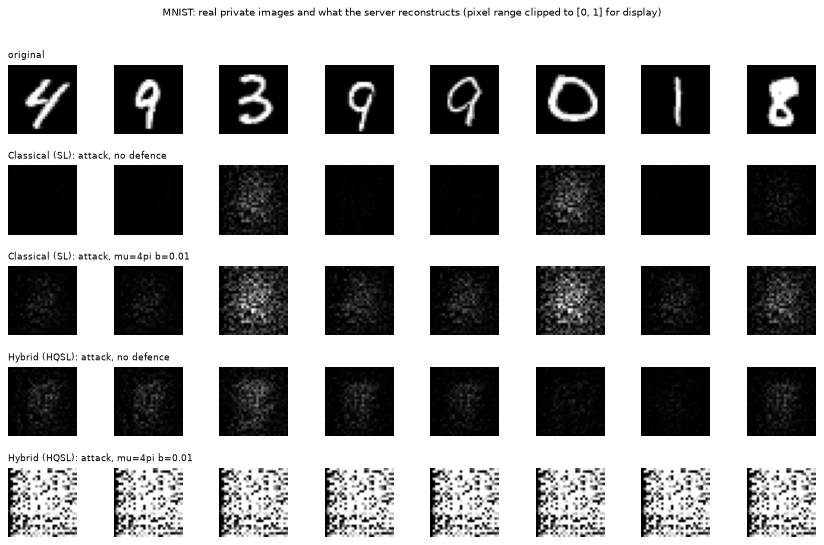

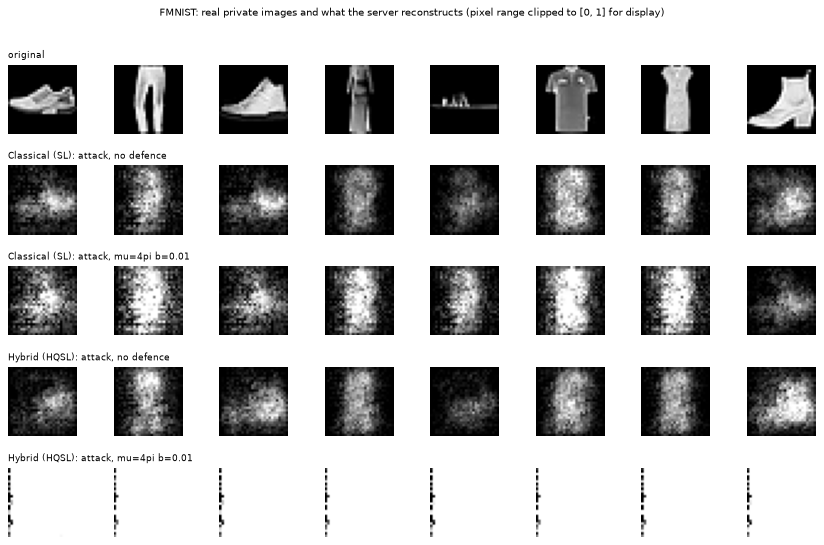

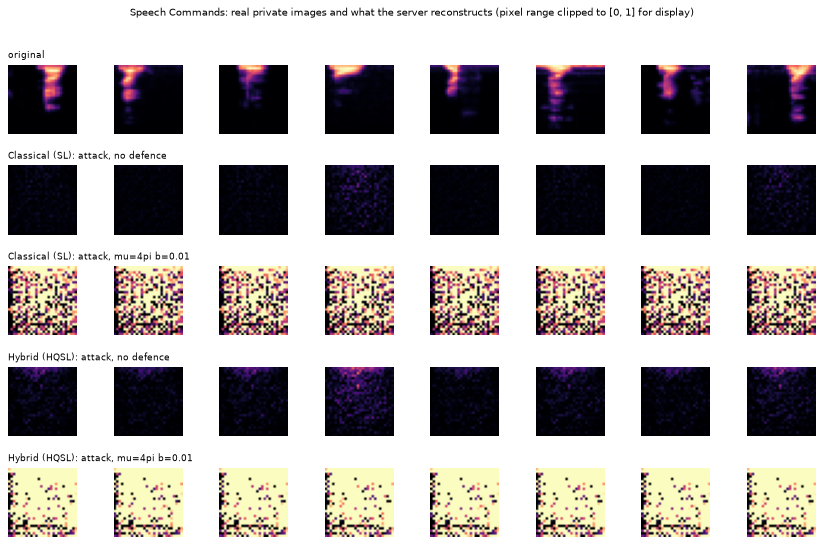

In [26]:
LABEL = {"SL": "Classical (SL)", "HQSL": "Hybrid (HQSL)"}
COL = {"SL": "#4C72B0", "HQSL": "#DD8452"}
for name in IMG_SETS:
    metrics = ["cosine", "mse", "dssim"] if name != "Speech Commands" else ["cosine", "dssim", "lsd"]
    fig, axes = plt.subplots(3, 4, figsize=(15, 8), sharex=True)
    for i, mt in enumerate(metrics):
        for j, b in enumerate(NOISE_B):
            ax = axes[i, j]
            for setting in ("SL", "HQSL"):
                s = sweep_df[(sweep_df.dataset == name) & (sweep_df.setting == setting) & (sweep_df.b == b)]
                ax.plot(s.mu.astype(int), s[mt], marker="o", color=COL[setting], label=LABEL[setting])
                ax.axhline(base.loc[(name, setting), mt], ls="--", color=COL[setting], alpha=0.7)
            if mt in ("mse", "lsd"): ax.set_yscale("log")
            ax.set_xticks(range(5)); ax.set_xticklabels(["0", "pi", "2pi", "3pi", "4pi"])
            if i == 0: ax.set_title(f"b = {b}")
            if j == 0: ax.set_ylabel(f"mean {mt.upper()}" + (" (log)" if mt in ("mse", "lsd") else ""))
            if i == 2: ax.set_xlabel("noise mean mu")
    axes[0, 0].legend(fontsize=7)
    plt.suptitle(f"{name}: reconstruction error vs Laplace-noise parameters (larger = better defence; dashed = noise-free baseline) - cf. Fig. 13", y=1.0)
    plt.tight_layout(); plt.show()

# qualitative results (cf. Fig. 16): original / attack without defence / attack with the defence mu = 4 pi, b = 0.01
for name in IMG_SETS:
    A = ATT[name]; n_show = 8
    rows = [("original", A["Xinf"][:n_show])]
    with torch.no_grad():
        for setting in ("SL", "HQSL"):
            Zc = A["Z_inf"][setting][:n_show]
            Zn = Zc + laplace_noise(Zc.shape, 4 * np.pi, 0.01, torch.Generator().manual_seed(SEED))
            rows.append((f"{LABEL[setting]}: attack, no defence", RECON[(name, setting, 1)](Zc)))
            rows.append((f"{LABEL[setting]}: attack, mu=4pi b=0.01", RECON[(name, setting, 1)](Zn)))
    fig, axes = plt.subplots(len(rows), n_show, figsize=(n_show * 1.3, len(rows) * 1.35))
    for r, (ttl, imgs) in enumerate(rows):
        for c in range(n_show):
            axes[r, c].imshow(imgs[c, 0].numpy(), cmap="gray" if name != "Speech Commands" else "magma", vmin=0, vmax=1); axes[r, c].axis("off")
        axes[r, 0].set_title(ttl, fontsize=8, loc="left")
    plt.suptitle(f"{name}: real private images and what the server reconstructs (pixel range clipped to [0, 1] for display)", fontsize=9, y=1.01)
    plt.tight_layout(); plt.show()


### Figs. 14-15: classification accuracy with the noise layer active

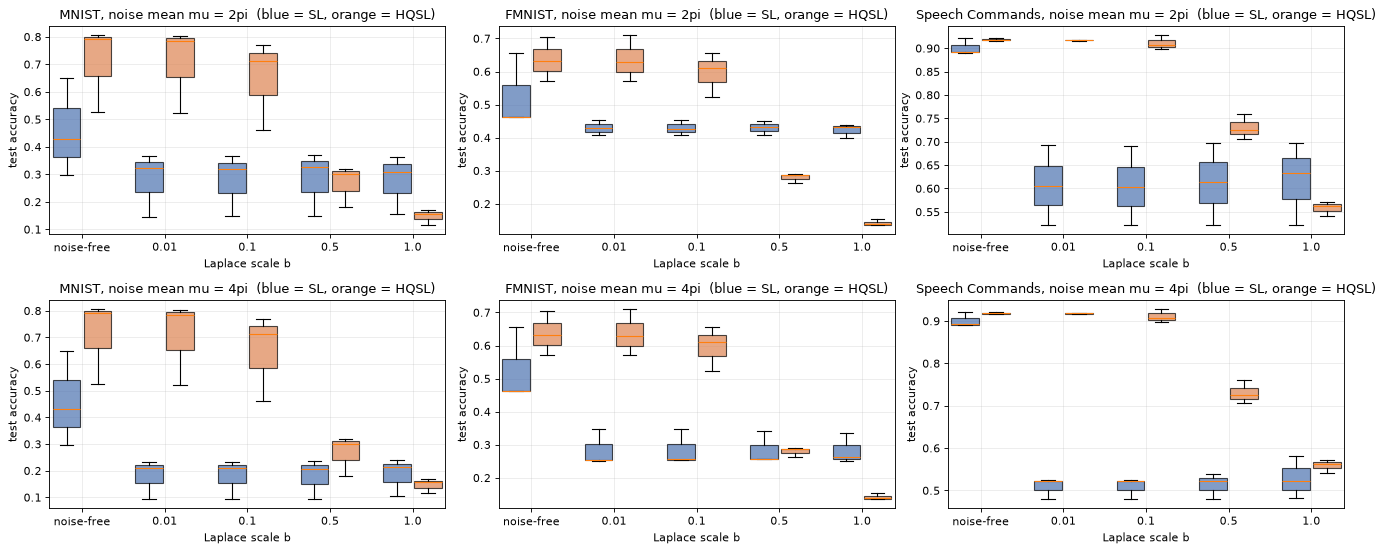

mean test accuracy over folds with the defence active (mu in {2pi, 4pi}):
mu                      noise-free    2pi                         4pi                     
b                       noise-free   0.01    0.1    0.5    1.0   0.01    0.1    0.5    1.0
dataset         setting                                                                   
MNIST           SL           0.459  0.279  0.278  0.282  0.275  0.179  0.179  0.179  0.185
                HQSL         0.708  0.703  0.648  0.267  0.147  0.703  0.648  0.267  0.147
FMNIST          SL           0.527  0.430  0.429  0.430  0.423  0.285  0.286  0.285  0.284
                HQSL         0.636  0.636  0.597  0.280  0.143  0.636  0.597  0.280  0.143
Speech Commands SL           0.901  0.607  0.605  0.611  0.618  0.509  0.509  0.513  0.529
                HQSL         0.919  0.917  0.911  0.731  0.559  0.917  0.911  0.731  0.559


In [27]:
util_rows = []
for name in IMG_SETS:
    d = DATASETS[name]
    for f, (tr, te) in enumerate(FOLDS[name]):
        _, _, Xte, yte = fold_tensors(name, tr, te)
        for setting in ("SL", "HQSL"):
            cl, sv = MODELS[(name, f, setting)]
            a, f1 = score(cl, sv, Xte, yte, "img"); util_rows.append(dict(dataset=name, fold=f, setting=setting, mu="noise-free", b="noise-free", accuracy=a, f1=f1))
            for mu_k in (2, 4):
                for b in NOISE_B:
                    a, f1 = score(cl, sv, Xte, yte, "img", noise=(mu_k * np.pi, b), gen=torch.Generator().manual_seed(SEED + f))
                    util_rows.append(dict(dataset=name, fold=f, setting=setting, mu=f"{mu_k}pi", b=str(b), accuracy=a, f1=f1))
util_df = pd.DataFrame(util_rows)

fig, axes = plt.subplots(2, 3, figsize=(17, 7), sharey=False)
cats = ["noise-free"] + [str(b) for b in NOISE_B]
for i, mu in enumerate(("2pi", "4pi")):
    for j, name in enumerate(IMG_SETS):
        ax = axes[i, j]
        for k, setting in enumerate(("SL", "HQSL")):
            data = [util_df[(util_df.dataset == name) & (util_df.setting == setting) & ((util_df.mu == "noise-free") if c == "noise-free" else (util_df.mu == mu) & (util_df.b == c))].accuracy.values for c in cats]
            bp = ax.boxplot(data, positions=np.arange(len(cats)) * 2.4 + k * 0.9, widths=0.8, patch_artist=True)
            for box in bp["boxes"]: box.set_facecolor(COL[setting]); box.set_alpha(0.7)
        ax.set_xticks(np.arange(len(cats)) * 2.4 + 0.45); ax.set_xticklabels(cats); ax.set_xlabel("Laplace scale b")
        ax.set_ylabel("test accuracy"); ax.set_title(f"{name}, noise mean mu = {mu[0]}pi  (blue = SL, orange = HQSL)")
plt.tight_layout(); plt.show()
tbl = util_df.pivot_table(index=["dataset", "setting"], columns=["mu", "b"], values="accuracy", sort=False).round(3)
print("mean test accuracy over folds with the defence active (mu in {2pi, 4pi}):"); print(tbl.to_string())


### Appendix E (other attackers), adaptive attacker (extension) and the scale argument

In [28]:
# Appendix E (Tables 6 and 7): reconstruction models 2 and 3 against the defence mu = 4 pi, b = 0.01; "noisy (noise-free baseline)"
appE_rows = []
for name in RECON_MODELS_2_3:
    for mid in (2, 3):
        for setting in ("SL", "HQSL"):
            clean, noisy = attack(name, setting, mid), attack(name, setting, mid, 4 * np.pi, 0.01, seed=SEED)
            appE_rows.append(dict(dataset=name, model=mid, setting=LABEL[setting], **{f"{k}": f"{noisy[k]:.3f} ({clean[k]:.3f})" for k in ("cosine", "mse", "dssim", "lsd")},
                                  worse_than_baseline=bool(noisy["cosine"] > clean["cosine"] or noisy["dssim"] > clean["dssim"])))
appE_df = pd.DataFrame(appE_rows)
print(appE_df.to_string(index=False))

# EXTENSION (not in the paper): how much of the defence survives an attacker who simply re-centres the received smashed data?
ext_rows = []
for name in IMG_SETS:
    for setting in ("SL", "HQSL"):
        for tag, kw in (("no defence", {}), ("defence mu=4pi b=0.01", dict(mu=4 * np.pi, b=0.01)), ("defence + median re-centring attacker", dict(mu=4 * np.pi, b=0.01, recentre=True))):
            r = attack(name, setting, 1, seed=SEED, **kw)
            ext_rows.append(dict(dataset=name, setting=LABEL[setting], scenario=tag, cosine=r["cosine"], mse=r["mse"], dssim=r["dssim"]))
ext_df = pd.DataFrame(ext_rows).round(4)
print("\nEXTENSION - adaptive attacker (reconstruction model 1):"); print(ext_df.to_string(index=False))

# scale argument: a shift of 4 pi = 12.6 rad is relatively huge for HQSL smashed data (they live on the scale of rotation angles) but not necessarily for SL
print("\nspread of the clean smashed data (std of z) vs the shift 4 pi = %.1f:" % (4 * np.pi))
print(pd.DataFrame({k: {LABEL[s]: round(v, 2) for s, v in dd.items()} for k, dd in Z_SCALE.items()}).T.to_string())


dataset  model        setting        cosine            mse         dssim           lsd  worse_than_baseline
 FMNIST      2 Classical (SL) 0.275 (0.186)  0.147 (0.071) 0.424 (0.392) 1.618 (1.500)                 True
 FMNIST      2  Hybrid (HQSL) 0.708 (0.199) 29.437 (0.081) 0.500 (0.398) 2.559 (1.531)                 True
 FMNIST      3 Classical (SL) 0.178 (0.150)  0.091 (0.059) 0.369 (0.348) 1.294 (1.164)                 True
 FMNIST      3  Hybrid (HQSL) 0.399 (0.133)  9.955 (0.055) 0.497 (0.319) 2.262 (1.124)                 True



EXTENSION - adaptive attacker (reconstruction model 1):
        dataset        setting                              scenario  cosine     mse  dssim
          MNIST Classical (SL)                            no defence  0.7373  0.1002 0.4639
          MNIST Classical (SL)                 defence mu=4pi b=0.01  0.6055  0.0943 0.4819
          MNIST Classical (SL) defence + median re-centring attacker  0.7311  0.0997 0.4648
          MNIST  Hybrid (HQSL)                            no defence  0.6146  0.0938 0.4704
          MNIST  Hybrid (HQSL)                 defence mu=4pi b=0.01  0.6323  2.5263 0.4965
          MNIST  Hybrid (HQSL) defence + median re-centring attacker  0.6037  0.0930 0.4705
         FMNIST Classical (SL)                            no defence  0.2042  0.0787 0.4168
         FMNIST Classical (SL)                 defence mu=4pi b=0.01  0.2495  0.1437 0.4380
         FMNIST Classical (SL) defence + median re-centring attacker  0.2055  0.0790 0.4183
         FMNIST  Hybrid

## 8. Paper versus this notebook

Every checkable claim of the paper, the number it reports, the number of this run, and a verdict. "reproduced" = within 2 accuracy points / 0.02 F1 (0.05 for the single-fold noisy-simulator rows); "not reached" / "exceeded" give the signed gap. In FAST_MODE the budgets are far below the paper's (see the configuration cell), so "not reached" there may reflect under-training rather than a failure of the paper's claim.

In [29]:
TOL = 0.02          # "reproduced" = within 2 accuracy points / 0.02 F1 of the paper's number
PAPER_T5 = {        # Table 5, circuit 6: dataset -> (HQSL acc, HQSL F1, SL acc, SL F1)
    "Botnet DGA": (0.920, 0.894, 0.919, 0.890), "Breast Cancer": (0.970, 0.961, 0.965, 0.953), "MNIST": (0.951, 0.951, 0.948, 0.948),
    "FMNIST": (0.839, 0.840, 0.805, 0.808), "Speech Commands": (0.960, 0.960, 0.949, 0.948)}
PAPER_FIG7_DELTA = {"Botnet DGA": (0.1, 0.4), "Breast Cancer": (0.6, 0.7), "MNIST": (0.4, 0.4), "FMNIST": (3.0, 4.0), "Speech Commands": (1.5, 1.5)}   # points

def verdict(nb, paper, tol=TOL):
    gap = nb - paper
    return ("reproduced" if abs(gap) <= tol else ("exceeded" if gap > 0 else "not reached")) + f" ({gap:+.3f})"

rows = []
sm = single_df.groupby(["dataset", "setting"])[["accuracy", "f1"]].mean()
ss = single_df.groupby(["dataset", "setting"])[["accuracy", "f1"]].std()
for name in DATASETS:
    ph_a, ph_f, pc_a, pc_f = PAPER_T5[name]
    rows.append(dict(claim=f"C1 {name}: HQSL acc / F1 (Table 5)", paper=f"{ph_a:.3f} / {ph_f:.3f}",
                     notebook=f"{sm.loc[(name, 'HQSL'), 'accuracy']:.3f} / {sm.loc[(name, 'HQSL'), 'f1']:.3f}",
                     verdict=verdict(sm.loc[(name, 'HQSL'), 'accuracy'], ph_a) + " | F1 " + verdict(sm.loc[(name, 'HQSL'), 'f1'], ph_f)))
    rows.append(dict(claim=f"C1 {name}: SL acc / F1 (Table 5)", paper=f"{pc_a:.3f} / {pc_f:.3f}",
                     notebook=f"{sm.loc[(name, 'SL'), 'accuracy']:.3f} / {sm.loc[(name, 'SL'), 'f1']:.3f}",
                     verdict=verdict(sm.loc[(name, 'SL'), 'accuracy'], pc_a) + " | F1 " + verdict(sm.loc[(name, 'SL'), 'f1'], pc_f)))
    da = (sm.loc[(name, 'HQSL'), 'accuracy'] - sm.loc[(name, 'SL'), 'accuracy']) * 100
    df_ = (sm.loc[(name, 'HQSL'), 'f1'] - sm.loc[(name, 'SL'), 'f1']) * 100
    pa, pf = PAPER_FIG7_DELTA[name]
    ok = abs(da - pa) <= 2 and abs(df_ - pf) <= 2
    rows.append(dict(claim=f"C1 {name}: HQSL - SL gain, points (Fig. 7)", paper=f"+{pa} / +{pf}", notebook=f"{da:+.2f} / {df_:+.2f}",
                     verdict=("reproduced" if ok else ("not reached" if da < pa - 2 or df_ < pf - 2 else "exceeded")) +
                             f" (fold std of accuracy: HQSL {ss.loc[(name, 'HQSL'), 'accuracy'] * 100:.1f}, SL {ss.loc[(name, 'SL'), 'accuracy'] * 100:.1f} points)"))

# C2: circuit study
cm = circ_df.groupby("circuit")["accuracy"].mean()
best = max((c for c in cm.index if c != "SL"), key=lambda c: cm[c])
for c in (7, 8, 6, 9, 10):
    rows.append(dict(claim=f"C2 Table 2, circuit {c}: accuracy (Fashion-MNIST)", paper=f"{PAPER_TABLE2[c][2]:.3f}", notebook=f"{cm[c]:.3f}", verdict=verdict(cm[c], PAPER_TABLE2[c][2])))
rows.append(dict(claim="C2 circuit 6 is the best of circuits 6-10", paper="yes", notebook=f"best = circuit {best}", verdict="reproduced" if best == 6 else "not reached"))
rows.append(dict(claim="C2 depth 8 / 6 parameters / equal PennyLane", paper="8 / 6", notebook="8 / 6 (asserted)", verdict="reproduced"))
rows.append(dict(claim="C3 split == centralised training", paper="identical", notebook=f"max weight difference {SPLIT_DIFF:.1e}", verdict="reproduced"))

# C4: noisy simulators
for _, r in noisy_df.iterrows():
    key = r.backend.replace(" (native-gate noise)", "")
    if key in PAPER_FIG8:
        pa = PAPER_FIG8[key][0]
        v = verdict(r.accuracy, pa, 0.05)
        if v.startswith("exceeded") and "p=" in r.backend:
            v = f"not reproduced: our accuracy is higher by {r.accuracy - pa:.2f}, the paper's drop is not seen"
        rows.append(dict(claim=f"C4 Fig. 8 {r.backend}: accuracy", paper=f"{pa:.3f}", notebook=f"{r.accuracy:.3f}", verdict=v + " [tolerance 0.05, single fold]"))
for b in ("ibm_sherbrooke", "ibm_strasbourg", "ibm_brussels"):
    rows.append(dict(claim=f"C4 Fig. 8 {b}: accuracy", paper=f"{PAPER_FIG8[b][0]:.3f}", notebook="-", verdict="cannot be checked (real hardware)"))
for tag, sel in (("gate-level noise", ~noisy_df.backend.str.contains("native")), ("native-gate noise", noisy_df.backend.str.contains("native"))):
    nd = noisy_df[noisy_df.backend.str.contains("p=") & sel]
    drop = nd.accuracy.values[0] - nd.accuracy.values[-1]
    rows.append(dict(claim=f"C4 accuracy falls with depolarising p ({tag}), p=0.05 -> 0.09", paper="0.89 -> 0.60", notebook=str(nd.accuracy.round(3).tolist()),
                     verdict="reproduced" if (np.diff(nd.accuracy.values) <= 0.01).all() and drop > 0.1 else "not reached (accuracy hardly falls)"))

# C5: clients
for name in DATASETS:
    for setting in ("SL", "HQSL"):
        s = mc_df[(mc_df.dataset == name) & (mc_df.setting == setting)].sort_values("K")
        rows.append(dict(claim=f"C5 {name} {setting}: accuracy K={s.K.iloc[0]} -> K={s.K.iloc[-1]}", paper="no significant drop",
                         notebook=f"{s.accuracy.iloc[0]:.3f} -> {s.accuracy.iloc[-1]:.3f}",
                         verdict=("reproduced" if s.accuracy.iloc[-1] >= s.accuracy.iloc[0] - 0.03 else f"not reached ({s.accuracy.iloc[-1] - s.accuracy.iloc[0]:+.3f})")
                                 + (" (weak evidence: the K=2 model is under-trained in FAST_MODE)" if FAST_MODE else "")))

# C6: reconstruction, mu in {2pi, 4pi}, b = 0.01
for name in IMG_SETS:
    mts = ["cosine", "dssim"] + (["lsd"] if name == "Speech Commands" else ["mse"])
    for setting in ("SL", "HQSL"):
        vals = []
        for mu_k in (2, 4):
            r = sweep_df[(sweep_df.dataset == name) & (sweep_df.setting == setting) & (sweep_df.mu == mu_k) & (sweep_df.b == 0.01)].iloc[0]
            b0 = base.loc[(name, setting)]
            vals.append(" ".join(f"{m}:{r[m] / max(b0[m], 1e-12):.2f}x" for m in mts))
        above = all(float(v.split(":")[1][:-1]) > 1.0 for vv in vals for v in vv.split())
        if setting == "HQSL":
            rows.append(dict(claim=f"C6 {name} HQSL: error / baseline at mu=2pi | 4pi, b=0.01", paper="> 1x (large)", notebook=" | ".join(vals),
                             verdict="reproduced" if above else "not reached (some metric <= baseline)"))
        else:   # the paper says the classical deviation is smaller (MNIST: 'minimal'), so no threshold is imposed on SL
            rows.append(dict(claim=f"C6 {name} SL: error / baseline at mu=2pi | 4pi, b=0.01", paper="smaller than hybrid", notebook=" | ".join(vals),
                             verdict="reported (no claim to test beyond the hybrid-vs-classical comparison below)"))
hyb_vs_cl = []
for name in IMG_SETS:
    mt = "cosine"; b0 = base[mt]
    r = {s: sweep_df[(sweep_df.dataset == name) & (sweep_df.setting == s) & (sweep_df.mu == 4) & (sweep_df.b == 0.01)].iloc[0][mt] / b0[(name, s)] for s in ("SL", "HQSL")}
    hyb_vs_cl.append((name, r["HQSL"] > r["SL"]))
rows.append(dict(claim="C6 deviation from baseline larger for HQSL than for SL (cosine, mu=4pi, b=0.01)", paper="yes (MNIST, FMNIST)", notebook=str(dict(hyb_vs_cl)),
                 verdict="reproduced" if all(v for _, v in hyb_vs_cl) else "partly / not reached"))

# C7: utility under the defence
for name in IMG_SETS:
    u = util_df[util_df.dataset == name].groupby(["setting", "mu", "b"])["accuracy"].mean()
    for setting in ("HQSL", "SL"):
        nf, d4, d2 = u[(setting, "noise-free", "noise-free")], u[(setting, "4pi", "0.01")], u[(setting, "2pi", "0.01")]
        exp = "keeps accuracy" if setting == "HQSL" else "accuracy drops"
        ok = (nf - d4 < 0.02 and nf - d2 < 0.02) if setting == "HQSL" else (nf - d4 > 0.05)
        rows.append(dict(claim=f"C7 {name} {setting}: accuracy noise-free -> mu=2pi|4pi, b=0.01", paper=exp, notebook=f"{nf:.3f} -> {d2:.3f} | {d4:.3f}",
                         verdict="reproduced" if ok else "not reached"))
cmp_df = pd.DataFrame(rows)
pd.set_option("display.max_colwidth", 110, "display.width", 250)
print(cmp_df.to_string(index=False))
import re
cmp_df["kind"] = cmp_df.verdict.apply(lambda v: next((k for k in ("reproduced", "not reached", "not reproduced", "exceeded", "cannot be checked", "reported") if v.startswith(k)), "other"))
print("\nverdict counts:", cmp_df.kind.value_counts().to_dict())
print(f"\nrun mode: FAST_MODE = {FAST_MODE}. " + ("The budgets are a small fraction of the paper's (see the configuration cell): absolute accuracies of the image models are "
      "far below the paper's because they are under-trained, so 'not reached' on those rows reflects the budget, not a refutation. Rows that follow from the "
      "mathematics (split == centralised, circuit resources, invariance of the quantum layer to 2 pi shifts) do not depend on it." if FAST_MODE else "Full budgets."))


                                                                          claim               paper                                                                   notebook                                                                                                    verdict
                                         C1 Botnet DGA: HQSL acc / F1 (Table 5)       0.920 / 0.894                                                              0.936 / 0.936                                                                 reproduced (+0.016) | F1 exceeded (+0.042)
                                           C1 Botnet DGA: SL acc / F1 (Table 5)       0.919 / 0.890                                                              0.934 / 0.934                                                                 reproduced (+0.015) | F1 exceeded (+0.044)
                                 C1 Botnet DGA: HQSL - SL gain, points (Fig. 7)         +0.1 / +0.4                                                       

## 9. Reading the paper critically

* **Is the gain quantum?** The gains of HQSL over SL are small (0.1 to 1.5 points, and 3 points on Fashion-MNIST) and of the same order as the fold-to-fold standard deviation of the experiments. The quantum layer outputs two *bounded, periodic* functions (values in [-1, 1]) of the three smashed features,
whereas the "classical counterpart" is an unbounded `Linear + ReLU`. A cos/sin or tanh twin would be the fair control to separate "quantum" from "bounded periodic non-linearity"; the paper does not run it (see exercise 1). A 2-qubit circuit simulated exactly is also trivially classically simulable.
* **The defence is a periodicity trick.** Adding mu = 2 pi k is invisible to the quantum layer only because `RX(z + 2 pi k) = +-RX(z)`. Any classical server whose first layer is periodic in z (for example `cos(Wz)`) is equally immune, so the benefit comes from the *encoding*, not from quantum mechanics.
  The server also receives the shifted values in the clear: our *median re-centring* attacker (section 7, extension) estimates the offset from public auxiliary data and removes it, which restores the attack. The paper's threat model assumes an attacker who does not adapt, and formal privacy guarantees (differential privacy) are left open by the authors.
* **A scale effect.** The smashed data of the HQSL client live on the scale of rotation angles, whereas the SL client is unconstrained; a shift of 4 pi = 12.6 rad is therefore *relatively* much larger for one than for the other (we print the spreads). Part of the "hybrid is harder to reconstruct" result may be a scale artefact rather than a property of the quantum layer.
* **Weak attack baselines.** Reconstructing a 784-pixel image from three numbers is poor even without noise (the paper's own baselines are far from 0 for MNIST), so much of the privacy comes from the 3-dimensional bottleneck itself. Only inference-time reconstruction is studied; training-time leakage, label leakage, membership inference and stronger attackers (models trained with more auxiliary data or with feature-space losses) are not.
* **Hardware claims.** Fig. 8 uses one fold and 200 test samples; the depolarising levels (p = 0.05-0.09) are "exaggerated" compared with calibrated device errors by the authors' own account, so the simulator rows say little about real devices. The three IBM back-ends in the paper are no longer reproducible.
* **Where the noise goes matters.** The paper does not say how its depolarising noise was attached to the circuit. We tried two placements (on the logical gates, and on IBM-like native `sx`/`x`/`cx` gates after transpilation). In both, the expectation values are strongly damped (the printed attenuation factors),
  yet the classical head keeps classifying correctly in our runs, so the sharp accuracy fall of Fig. 8 (0.89 to 0.60) is not seen. The result depends on the trained head and on the noise placement; it should be read as "robust to damping of the quantum outputs", not as evidence about real devices.
* **The classical twin is a fragile control.** `Linear(3 -> 2) + ReLU` can lose a unit at the start of training (a "dead" ReLU), after which the whole SL model learns very slowly; the per-fold results printed in section 3 can show runs where SL stays at the majority class while HQSL trains normally (in the FAST_MODE run committed with this notebook, SL on Breast Cancer fold 0).
  Part of any HQSL-over-SL gain (especially under short training budgets) may therefore be an optimisation effect of the bounded quantum layer, which is exactly why exercise 1 asks for a better twin.
* **Compute cost.** The paper reports 1 h (569 samples) to 9 h (MNIST) of simulation per 5-fold run and up to 500 h for 8 qubits (Fig. 5): the quantum layer buys at best a small accuracy gain at a large simulation cost.

## 10. Exercises

1. **A fair classical twin.** Replace `ClassicalLayer` by `Linear(3 -> 2)` followed by `tanh` or by `sin`, and repeat section 3 on Fashion-MNIST. Does the quantum layer still win? What does that say about the source of the gain?
2. **Circuit design.** Use `circuit_spec` as a template to add a circuit with RX encoding but without the CZ gates, or with the encoding gates swapped to RY. Check with the PennyLane assertion cell that your simulator agrees, then add it to Table 2.
3. **Break the defence.** Make the attacker stronger: train the reconstruction model on smashed data that were *already* perturbed with random shifts of 2 pi k (data augmentation with the attacker's own noise). How much of the defence survives for b = 0.01 and b = 0.1?
4. **Make SL immune too.** Give the classical server a periodic first layer, `[cos(z), sin(z)]` before `Linear`, and rerun the utility experiment of section 7. Is the privacy-utility advantage of HQSL still there?
5. **Scale, not quantum?** Add a penalty that keeps the SL client's smashed data inside [-pi, pi] and repeat the reconstruction sweep: does the gap between the classical and the hybrid setting shrink?